# Cross-dataset MSN integration — SlideTags + NucSeq + HD (Handsaker) — scVI/scANVI + scArches surgery

**Strategy** (same pattern as `script/microglia_mapping/08b_microglia_state_mapping_surgery_apply_query.ipynb`):

1. Train scVI + scANVI on **HD (Handsaker)** only → this is the **baseline / reference**.
2. Concatenate **NucSeq + SlideTags** into a single **query**, and map it onto the HD reference with scArches surgery (`load_query_data`).
3. Get a single joint latent space for all three datasets.

Design choices specific to this 3-way merge (see markdown notes inline):
- Only cells with `ct_for_deg` in a chosen list are used (edit the list in **Section 2** — default: MSN types).
- Donor IDs are harmonized across NucSeq/SlideTags, because **the same donors were profiled in both modalities** (see **Section 4**).
- The scVI `batch` key is the **technical pooling/library unit** (library / reaction), not donor identity — donor identity is kept as separate metadata (`donor_id_unified`) so paired donors can be inspected/compared without being treated as a technical batch effect to remove.
- Gene universe is restricted to genes present in **all three datasets** (Ensembl IDs, which all three use as `var_names`) before HVG selection, so no reference HVG is ever missing from the query (see **Section 3**).

**Independent question — does restricting to a subset of cell types (e.g. only MSNs) hurt the model's ability to learn?**
Short answer: no, as long as each batch/donor still has enough cells of the chosen type(s) (rule of thumb: ≥50–100 cells per batch, checked in Section 5). scVI/scANVI only need to resolve variation *within the cells you show it*. Restricting to MSNs removes the (easy, large) variance between very different cell classes and lets latent dimensions + the classifier focus capacity on the finer distinctions between MSN subtypes — usually this **improves** resolution of subtypes rather than hurting it. The main risk is the opposite direction: if you subset so hard that individual batches/donors are left with too few cells, the batch-effect estimate for that batch becomes noisy. That's why Section 5 prints per-donor, per-dataset cell counts for the chosen cell types before training.


In [1]:
%load_ext autoreload
%autoreload 2

import os
import re
import itertools

import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import scvi
import matplotlib.pyplot as plt

scvi.settings.seed = 42
print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}")


Seed set to 42


scvi-tools: 1.4.0.post1, scanpy: 1.11.5


/tmp/ipykernel_337485/1800645886.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scvi-tools: {scvi.__version__}, scanpy: {sc.__version__}")


## 1 · Config

In [2]:
BASE_PATH = "/home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI"
os.makedirs(BASE_PATH, exist_ok=True)

RAW_PATHS = {
    "HD":        "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad",
    "nucseq":    "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad",
    "slidetags": "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad",
}

REF_NAME = "HD"                       # baseline / reference dataset
QUERY_NAMES = ["nucseq", "slidetags"]  # mapped onto the reference jointly, as one query

CELL_TYPE_COL = "Group_name"    # used ONLY in Section 2 to choose which cells to integrate (coarse MapMyCells label)
TRAIN_LABEL_COL = "ct_for_deg"  # used for scANVI training + predicted labels (finer, project-curated subtype)

# Set SUBSET_RUN = True for a quick smoke-test run on a small fraction of the data
# (e.g. to sanity-check the pipeline end-to-end before committing to a full-scale training run)
SUBSET_RUN = False
MAX_CELLS_PER_TYPE = 3000   # cap per TRAIN_LABEL_COL category, per dataset, when SUBSET_RUN is True

# Optional: restrict integration to a single disease status and/or a single sex.
# Both None = keep everything. Applied per-dataset in Section 5 (load_and_prepare), before
# the tiny-batch drop -- so MIN_BATCH_SIZE is evaluated on the already-restricted population.
FILTER_STATUS = "Diseased"   # e.g. "Diseased" or "Healthy"
FILTER_SEX = None      # e.g. "Male" or "Female"

# Used by the FILTER_STATUS check above (separate from the is_diseased boolean map further
# below in the notebook, which downstream plotting cells rely on -- kept as human-readable
# strings here since that's what you compare FILTER_STATUS against).
RAW_CONDITION_COL = {"HD": "Status", "nucseq": "condition", "slidetags": "condition"}
CONDITION_MAP = {
    "HD":        {"Case": "Diseased", "Control": "Healthy"},
    "nucseq":    {"XDP": "Diseased", "Control": "Healthy"},
    "slidetags": {"diseased": "Diseased", "healthy": "Healthy"},
}

# Set USE_SCANVI = False to skip the supervised scANVI classifier entirely and train/map with plain
# unsupervised scVI instead (both the reference and the scArches surgery step use scVI.load_query_data
# rather than SCANVI.load_query_data). Useful when you don't trust TRAIN_LABEL_COL for a specific
# question -- e.g. checking whether a population like "-Phase_D" exists in NucSeq at all, independent
# of whether NucSeq's own separate labeling pipeline ever named a cluster that. In this mode there is
# no "predicted_scanvi" column produced -- inspect the shared latent space / your own clustering instead.
USE_SCANVI = True

# Technical pooling/library unit per dataset -> used as the scVI `batch` key
# (donor identity is NOT used here, see Section 4 for why)
BATCH_COL_MAP = {
    "HD":        "reaction",     # HD "Village" pooled reactions
    "nucseq":    "library",      # NucSeq multiplexed pool
    "slidetags": "Batch",   # SlideTags puck/capture area
}

# Donor column per dataset (raw, dataset-specific format)
DONOR_COL_MAP = {
    "HD":        "DONOR",
    "nucseq":    "donor_id",
    "slidetags": "donor_id",
}

# Sex column per dataset -- collected differently across datasets, see Section 5 harmonization cell.
# SlideTags/NucSeq are ~all male because XDP is X-linked; HD is a balanced HD cohort.
RAW_SEX_COL = {"HD": "Sex", "nucseq": "sex", "slidetags": "sex"}
SEX_MAP = {
    "HD":        {"Male": "Male", "Female": "Female"},
    "nucseq":    {"M": "Male", "F": "Female"},
    "slidetags": {"male": "Male", "female": "Female"},
}

LABELS_KEY  = "celltype_scanvi"
UNLABELLED  = "Unknown"
MIN_BATCH_SIZE = 100   # drop batches with fewer cells than this (too few cells to estimate a batch effect)

N_TOP_GENES        = 3000
SCVI_MAX_EPOCHS    = 25
SCANVI_MAX_EPOCHS  = 15
SURGERY_EPOCHS     = 20
N_SAMPLES_PER_LABEL = 100
BATCH_SIZE          = 512
CONF_THRESHOLD       = 0.8

arches_params = dict(
    use_layer_norm="both",
    use_batch_norm="none",
    encode_covariates=True,
    dropout_rate=0.2,
    n_layers=2,
    n_latent=30,
    gene_likelihood="nb",
)


## 2 · Choose which cells to integrate

**Edit `CELL_TYPES_TO_INTEGRATE` below** to change what gets integrated. This filter is applied to **all three datasets, including the HD baseline** — i.e. the reference is trained only on the chosen cell type(s) too, so the whole shared latent space is specific to them.

The default below is all MSN subtypes (these category names are identical across the three datasets' `ct_for_deg` column, confirmed by inspection).

In [3]:
df = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/SlideTags_XDP_metadata/XDP Slidetags - CellBender Terra table - cb.csv")
df = df[["donor_id", "Batch"]]

In [4]:
CELL_TYPES_TO_INTEGRATE = [
    "Matrix_D1",
    "Matrix_D2",
    "Patch_D1",
    "Patch_D2",
    "eMSN_D1D2",
    "eMSN_NUDAP",
    "eMSN_StrioMat",
]

CELL_TYPES_TO_INTEGRATE = [
    "STRd D1 Matrix MSN",
    "STRd D1 Striosome MSN",
    "STRv D1 MSN",

    "STRd D2 Matrix MSN",
    "STRd D2 Striosome MSN",
    "STRv D2 MSN",

    # "STRd D2 StrioMat Hybrid MSN",
    # "STR D1D2 Hybrid MSN",
    # "STRv D1 NUDAP MSN",
]

# other options you could swap in instead, e.g.:
# CELL_TYPES_TO_INTEGRATE = ["Microglia", "Macrophages"]
# CELL_TYPES_TO_INTEGRATE = ["Astrocyte"]


In [5]:
_backed = {}

for name, p in RAW_PATHS.items():
    print(f"Loading dataset: {name}")
    _backed[name] = sc.read_h5ad(p, backed="r")


Loading dataset: HD
Loading dataset: nucseq
Loading dataset: slidetags


In [6]:
for name, a in _backed.items():
    print(f"Processing dataset: {name}")
    vc = a.obs[CELL_TYPE_COL].value_counts()
    n_sel = vc.reindex(CELL_TYPES_TO_INTEGRATE).fillna(0).astype(int)
    print(f"--- {name} ({a.n_obs} cells total) ---")
    print(n_sel)
    missing = [ct for ct in CELL_TYPES_TO_INTEGRATE if ct not in vc.index or vc.get(ct, 0) == 0]
    if missing:
        print(f"  WARNING: not present in {name}: {missing}")
    print()


Processing dataset: HD
--- HD (581273 cells total) ---
Group_name
STRd D1 Matrix MSN       48558
STRd D1 Striosome MSN    19780
STRv D1 MSN              24654
STRd D2 Matrix MSN       43363
STRd D2 Striosome MSN    14421
STRv D2 MSN              20116
Name: count, dtype: int64

Processing dataset: nucseq
--- nucseq (231080 cells total) ---
Group_name
STRd D1 Matrix MSN       7896
STRd D1 Striosome MSN    5336
STRv D1 MSN              7418
STRd D2 Matrix MSN       9321
STRd D2 Striosome MSN    4069
STRv D2 MSN              6271
Name: count, dtype: int64

Processing dataset: slidetags
--- slidetags (742896 cells total) ---
Group_name
STRd D1 Matrix MSN       12718
STRd D1 Striosome MSN    16268
STRv D1 MSN              35879
STRd D2 Matrix MSN       20889
STRd D2 Striosome MSN    10495
STRv D2 MSN              31677
Name: count, dtype: int64



## 3 · Gene overlap across the three datasets

All three datasets already use **Ensembl gene IDs as `var_names`** (confirmed by inspection), so overlap is computed on `var_names` directly rather than on the `gene_symbol` column. This matters here: HD's `gene_symbol` annotation is older/different, so symbol-based overlap with HD is ~10k genes lower than Ensembl-ID-based overlap even though the underlying genes mostly do match (SlideTags vs NucSeq symbols agree almost perfectly with each other, HD's don't — an annotation-vintage difference, not a real biological gap). Always use Ensembl IDs to join genes across these datasets.

In [7]:
var_names_sets = {name: set(a.var_names) for name, a in _backed.items()}

# make explicit which identifier system COMMON_GENES is actually built from
for name, a in _backed.items():
    is_ensembl = a.var_names.str.match(r"^ENSG\d+").mean()
    print(f"{name}: var_names index name={a.var_names.name!r}, "
          f"example={list(a.var_names[:2])}, {is_ensembl:.0%} look like Ensembl IDs (ENSG...)")
    assert is_ensembl > 0.95, f"{name}: var_names doesn't look like Ensembl IDs -- check before trusting the overlap below"

print("\n=> overlap below is computed on var_names (Ensembl gene IDs), NOT on the gene_symbol column\n")

print("Pairwise overlap (Ensembl IDs, i.e. var_names):")
for a, b in itertools.combinations(var_names_sets, 2):
    print(f"  {a} ({len(var_names_sets[a])}) vs {b} ({len(var_names_sets[b])}): {len(var_names_sets[a] & var_names_sets[b])}")

COMMON_GENES = sorted(set.intersection(*var_names_sets.values()))
print(f"\nGenes shared by all {len(var_names_sets)} dataset(s) (by Ensembl ID): {len(COMMON_GENES)}")


HD: var_names index name=None, example=['ENSG00000121410', 'ENSG00000268895'], 100% look like Ensembl IDs (ENSG...)
nucseq: var_names index name='ensamble_id', example=['ENSG00000223972', 'ENSG00000243485'], 96% look like Ensembl IDs (ENSG...)
slidetags: var_names index name='ensembl_id', example=['ENSG00000290825', 'ENSG00000243485'], 100% look like Ensembl IDs (ENSG...)

=> overlap below is computed on var_names (Ensembl gene IDs), NOT on the gene_symbol column

Pairwise overlap (Ensembl IDs, i.e. var_names):
  HD (36943) vs nucseq (38601): 30692
  HD (36943) vs slidetags (37588): 31793
  nucseq (38601) vs slidetags (37588): 35694

Genes shared by all 3 dataset(s) (by Ensembl ID): 30589


In [8]:
# Symbol-based overlap, just to show the annotation-vintage caveat above.
# This uses the `gene_symbol` COLUMN (gene names), a completely separate identifier
# system from var_names (Ensembl IDs) used everywhere else in this notebook.
symbol_sets = {name: set(a.var["gene_symbol"].astype(str)) for name, a in _backed.items()}
for name, a in _backed.items():
    print(f"{name}: gene_symbol example={list(a.var['gene_symbol'].astype(str)[:3])}")

print("\nPairwise overlap (gene_symbol, i.e. gene NAMES -- for comparison only, DO NOT use this to subset):")
for a, b in itertools.combinations(symbol_sets, 2):
    print(f"  {a} vs {b}: {len(symbol_sets[a] & symbol_sets[b])}")

print("\n=> COMMON_GENES (used everywhere downstream) is the Ensembl-ID overlap above, not this one.")


HD: gene_symbol example=['A1BG', 'A1BG-AS1', 'A1CF']
nucseq: gene_symbol example=['DDX11L1', 'MIR1302-2HG', 'FAM138A']
slidetags: gene_symbol example=['DDX11L2', 'MIR1302-2HG', 'FAM138A']

Pairwise overlap (gene_symbol, i.e. gene NAMES -- for comparison only, DO NOT use this to subset):
  HD vs nucseq: 20738
  HD vs slidetags: 20988
  nucseq vs slidetags: 35171

=> COMMON_GENES (used everywhere downstream) is the Ensembl-ID overlap above, not this one.


## 4 · Donor ID harmonization

NucSeq and SlideTags are **two modalities of the same XDP cohort**, and several donors were profiled in **both** — so the same person can appear twice in the merged data, just under different assays. HD (Handsaker) is a **separate cohort/biobank** with a completely different donor ID scheme (`S#####` vs `SCF-YY-###` / `PCMC-YY-###`), so no overlap is expected there.

Donor IDs are not written consistently even within NucSeq/SlideTags (`SCF-22-057` vs `SCF_22-057CM`, separator and multiplexing-batch suffix differ) — same normalization issue as the VCF donor matching for GWAS. Normalize before comparing.

This unified ID is stored as metadata (`donor_id_unified`) for bookkeeping/plotting (e.g. to confirm the same donor's cells from both modalities land near each other in the joint latent space, or to avoid pseudoreplication in downstream per-donor stats). It is **not** used as the scVI batch key — the batch key stays the technical pooling unit (Section 1), since the two modalities have very different technical batch effects for the same biological donor.

In [9]:
def normalize_donor_id(x):
    """Normalize donor IDs across NucSeq/SlideTags: uppercase, unify separators,
    strip multiplexing-pool suffixes like 'CM', 'CF', 'CM2', 'CM6'."""
    x = str(x).strip().upper()
    if x in ("NAN", "UNASSIGNED", "NA", ""):
        return None
    x = x.replace("_", "-")
    m = re.match(r"^([A-Z]+)-?(\d+)-?(\d+)", x)
    if m:
        prefix, a, b = m.groups()
        return f"{prefix}-{a}-{b}"
    return x

# Datasets whose raw donor_id format needs harmonizing. HD's own S##### IDs are
# already unique/consistent -- running them through normalize_donor_id would actually
# mangle them (the regex would split "S00002" into a bogus "S-0000-2"), so HD is excluded.
NORMALIZE_DONOR_IDS = {"nucseq", "slidetags"}

donor_ids = {name: _backed[name].obs[DONOR_COL_MAP[name]].astype(str) for name in RAW_PATHS}

donor_id_unified = {
    name: (ids.map(normalize_donor_id) if name in NORMALIZE_DONOR_IDS else ids)
    for name, ids in donor_ids.items()
}

# donor overlap is only expected/meaningful between nucseq and slidetags (both XDP);
# only check it if both happen to be present in this run
overlap_pair = [name for name in ("nucseq", "slidetags") if name in donor_id_unified]
if len(overlap_pair) == 2:
    a_name, b_name = overlap_pair
    shared_nucseq_slidetags = set(donor_id_unified[a_name].dropna()) & set(donor_id_unified[b_name].dropna())
    print(f"{a_name} donors: {donor_id_unified[a_name].nunique()}")
    print(f"{b_name} donors: {donor_id_unified[b_name].nunique()}")
    print(f"Donors shared between {a_name} and {b_name}: {len(shared_nucseq_slidetags)}")
    print(sorted(shared_nucseq_slidetags))
else:
    shared_nucseq_slidetags = set()
    print(f"Only {overlap_pair or 'neither of nucseq/slidetags'} present this run -- no donor overlap to check.")

# sanity check: HD's ID namespace never collides with any other dataset's (normalized) IDs
if "HD" in donor_id_unified:
    other_ids = set().union(*(
        set(ids.dropna()) for name, ids in donor_id_unified.items() if name != "HD"
    ))
    assert not (set(donor_id_unified["HD"].dropna().unique()) & other_ids)


nucseq donors: 47
slidetags donors: 12
Donors shared between nucseq and slidetags: 12
['SCF-18-003', 'SCF-18-006', 'SCF-19-014', 'SCF-20-024', 'SCF-20-025', 'SCF-20-026', 'SCF-21-032', 'SCF-22-043', 'SCF-22-057', 'SCF-22-065', 'SCF-23-068', 'SCF-23-075']


## 5 · Subset each dataset: chosen cell types × common genes, load to memory

In [10]:
def load_and_prepare(name):
    print(name)

    a = sc.read_h5ad(RAW_PATHS[name], backed="r")

    for layer in list(a.layers.keys()):
        del a.layers[layer]          # drop counts+log1p_norm here; X already has the raw counts
    for key in list(a.obsp.keys()):
        del a.obsp[key]
    for key in list(a.obsm.keys()):
        if not (name == "slidetags" and key == "spatial"):
            del a.obsm[key]   # keep SlideTags' aligned spatial coords just long enough to copy into obs below

    mask = a.obs[CELL_TYPE_COL].isin(CELL_TYPES_TO_INTEGRATE)

    a = a[mask].to_memory().copy()   # subset rows first, while still backed
    a = a[:, COMMON_GENES].copy()    # subset columns once already in memory

    if name == "HD":
        print("Roming  cell type")
        a = a[a.obs["ct_for_deg"].isin([
            '-Low_quality',
            '-Phase_D',
            '-fake_phase_D',
            'Matrix_D1',
            'Matrix_D2',
            'Patch_D1',
            'Patch_D2']
            )].copy()

    if name == "slidetags":
        # obs["x"]/["y"] are per-library/per-puck RAW coordinates (independent local frames);
        # obsm["spatial"] is the cross-puck ALIGNED coordinates -- keep the aligned ones as obs
        # columns so they survive anndata.concat with HD/nucseq (obsm keys don't survive concat
        # unless present in every object; obs columns do, NaN-filled for the other two datasets)
        a.obs["spatial_x"] = a.obsm["spatial"][:, 0]
        a.obs["spatial_y"] = a.obsm["spatial"][:, 1]
        del a.obsm["spatial"]

    if SUBSET_RUN:
        keep_names = []
        for ct, idx in a.obs.groupby(TRAIN_LABEL_COL, observed=True).groups.items():
            n = min(len(idx), MAX_CELLS_PER_TYPE)
            keep_names.append(pd.Series(idx).sample(n=n, random_state=42).values)
        keep_names = np.concatenate(keep_names)
        a = a[keep_names].copy()
        print(f"  SUBSET_RUN: capped to {MAX_CELLS_PER_TYPE} cells per '{TRAIN_LABEL_COL}' -> {a.n_obs} cells")

    if name == "HD":
        print("Adding village to HD metadata")
        a.obs["village"] = a.obs["reaction"].str.split("_").str[0]

    if name == "slidetags":
        print("Adding batch to slidetags metadata")
        a.obs["Batch"] = a.obs["donor_id"].map(df.set_index("donor_id")["Batch"].to_dict())

    a.layers["counts"] = a.layers["counts"].copy() if "counts" in a.layers else a.X.copy()
    a.X = a.layers["counts"].copy()

    a.obs["dataset"] = name
    a.obs["donor_id_unified"] = donor_id_unified[name].loc[a.obs_names].values
    a.obs["batch"] = name + "__" + a.obs[BATCH_COL_MAP[name]].astype(str)
    a.obs[CELL_TYPE_COL] = a.obs[CELL_TYPE_COL].astype(str)
    a.obs[TRAIN_LABEL_COL] = a.obs[TRAIN_LABEL_COL].astype(str)

    # harmonize sex across datasets (collected differently, see Section 1 SEX_MAP) --
    # categories must stay within {"Male","Female"}: scArches surgery does NOT grow new
    # embedding rows for unseen categorical_covariate_keys values (unlike batch_key),
    # so any cell with unmapped/missing sex is dropped rather than bucketed as "Unknown"
    a.obs["sex"] = a.obs[RAW_SEX_COL[name]].astype(str).str.strip().map(SEX_MAP[name])
    n_missing_sex = a.obs["sex"].isna().sum()
    if n_missing_sex:
        print(f"  dropping {n_missing_sex} cells with unknown/missing sex")
    a = a[a.obs["sex"].notna()].copy()

    # optional: restrict to a single disease status and/or sex (Section 1 FILTER_STATUS/FILTER_SEX)
    if FILTER_STATUS is not None:
        status = a.obs[RAW_CONDITION_COL[name]].astype(str).str.strip().map(CONDITION_MAP[name])
        a = a[status == FILTER_STATUS].copy()
        print(f"  FILTER_STATUS='{FILTER_STATUS}': kept {a.n_obs} cells")
    if FILTER_SEX is not None:
        a = a[a.obs["sex"] == FILTER_SEX].copy()
        print(f"  FILTER_SEX='{FILTER_SEX}': kept {a.n_obs} cells")

    # drop batches with too few cells to estimate a batch effect
    batch_counts = a.obs["batch"].value_counts()
    a = a[a.obs["batch"].isin(batch_counts[batch_counts >= MIN_BATCH_SIZE].index)].copy()

    a.var_names_make_unique()
    print(f"{name}: {a.shape} after cell-type + gene filtering (+ tiny-batch removal)")
    return a

 
adatas = {}

for name in RAW_PATHS:
    adatas[name] = load_and_prepare(name)

del _backed


HD
Roming  cell type
Adding village to HD metadata
  FILTER_STATUS='Diseased': kept 45224 cells
HD: (45224, 30589) after cell-type + gene filtering (+ tiny-batch removal)
nucseq
  FILTER_STATUS='Diseased': kept 15536 cells
nucseq: (15536, 30589) after cell-type + gene filtering (+ tiny-batch removal)
slidetags
Adding batch to slidetags metadata
  FILTER_STATUS='Diseased': kept 78502 cells
slidetags: (78502, 30589) after cell-type + gene filtering (+ tiny-batch removal)


In [11]:
# Unified disease/control flag across the 3 studies (kept alongside each dataset's own condition/Status column, not a replacement for it)
condition_map = {
    "HD":        {"Case": True, "Control": False},
    "nucseq":    {"XDP": True, "Control": False},
    "slidetags": {"diseased": True, "healthy": False},
}
raw_condition_col = {"HD": "Status", "nucseq": "condition", "slidetags": "condition"}
for name, a in adatas.items():
    # .str.strip(): SlideTags has a "diseased " (trailing space) category alongside "diseased"
    a.obs["is_diseased"] = a.obs[raw_condition_col[name]].astype(str).str.strip().map(condition_map[name])
    assert a.obs["is_diseased"].notna().all(), f"{name}: unmapped condition value(s) {a.obs.loc[a.obs['is_diseased'].isna(), raw_condition_col[name]].unique()}"


In [12]:
# QC: per-donor cell counts for the chosen cell type(s), per dataset
# (relevant to the "does subsetting hurt training" question above -- a batch/donor
# with very few cells here will have a noisy batch-effect estimate)
for name, a in adatas.items():
    print(f"--- {name}: cells per donor (chosen cell types) ---")
    print(a.obs.groupby("donor_id_unified", observed=True).size().sort_values(ascending=False).describe())
    print()


--- HD: cells per donor (chosen cell types) ---
count      50.000000
mean      904.480000
std       953.004256
min         1.000000
25%        96.500000
50%       473.000000
75%      1646.250000
max      3075.000000
dtype: float64

--- nucseq: cells per donor (chosen cell types) ---
count      30.000000
mean      517.866667
std       328.055791
min        62.000000
25%       266.500000
50%       445.500000
75%       673.000000
max      1374.000000
dtype: float64

--- slidetags: cells per donor (chosen cell types) ---
count        8.000000
mean      9812.750000
std       7724.579522
min       1745.000000
25%       4835.500000
50%       8103.500000
75%      12699.500000
max      21502.000000
dtype: float64



## PART A — Train reference (scVI + scANVI) on HD (baseline)

Run once. Re-run this part if `CELL_TYPES_TO_INTEGRATE` changes.

In [13]:
ref = adatas[REF_NAME].copy()
ref.obs[LABELS_KEY] = ref.obs[TRAIN_LABEL_COL].astype(str)

# "counts" layer/X are raw counts (set in Section 5) -- keep them raw, normalize into a separate layer only
ref.layers["log1p_norm"] = ref.layers["counts"].copy()
sc.pp.normalize_total(ref, target_sum=1e4, layer="log1p_norm")
sc.pp.log1p(ref, layer="log1p_norm")

sc.pp.highly_variable_genes(ref, n_top_genes=N_TOP_GENES, flavor="seurat_v3", layer="counts")
ref = ref[:, ref.var.highly_variable].copy()
print(f"Reference after HVG: {ref.shape}")
print(ref.obs[LABELS_KEY].value_counts())


Reference after HVG: (45224, 3000)
celltype_scanvi
Matrix_D1        21230
Matrix_D2        14249
Patch_D1          4710
Patch_D2          2808
-Phase_D          1402
-Low_quality       752
-fake_phase_D       73
Name: count, dtype: int64


In [14]:
# "sex" is only a meaningful covariate if both sexes are actually present -- FILTER_SEX
# collapses it to a single constant value, so drop it from the model in that case
covariate_keys = None if FILTER_SEX is not None else ["sex"]
if FILTER_SEX is not None:
    print(f"FILTER_SEX='{FILTER_SEX}': sex is constant, not registering it as a covariate")

scvi.model.SCVI.setup_anndata(ref, layer="counts", batch_key="batch", categorical_covariate_keys=covariate_keys)
scvi_ref = scvi.model.SCVI(ref, **arches_params)
scvi_ref.train(
    max_epochs=SCVI_MAX_EPOCHS,
    early_stopping=True,
    batch_size=BATCH_SIZE,
    datasplitter_kwargs={"num_workers": 16},
)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/25 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=25` reached.


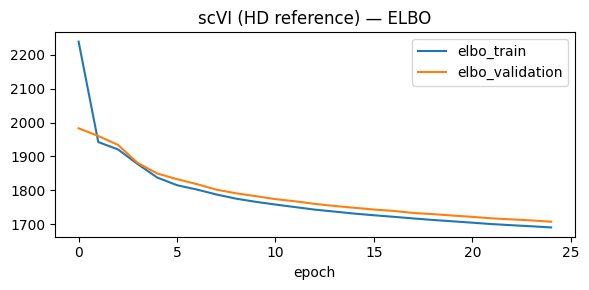

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
scvi_ref.history["elbo_train"].plot(ax=ax, label="train")
scvi_ref.history["elbo_validation"].plot(ax=ax, label="validation")
ax.set(title="scVI (HD reference) — ELBO"); ax.legend()
plt.tight_layout(); plt.show()


In [16]:
if USE_SCANVI:
    scanvi_ref = scvi.model.SCANVI.from_scvi_model(
        scvi_ref,
        unlabeled_category=UNLABELLED,
        labels_key=LABELS_KEY,
    )
    scanvi_ref.train(
        max_epochs=SCANVI_MAX_EPOCHS,
        n_samples_per_label=N_SAMPLES_PER_LABEL,
        batch_size=BATCH_SIZE,
        datasplitter_kwargs={"num_workers": 16},
    )
else:
    # no supervised step -- reuse the plain scVI model under the same variable name so
    # downstream cells (get_latent_representation, save, surgery) keep working unchanged
    scanvi_ref = scvi_ref
    print("USE_SCANVI=False: skipping scANVI training, using plain unsupervised scVI reference.")


INFO     Training for 15 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/15 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=15` reached.


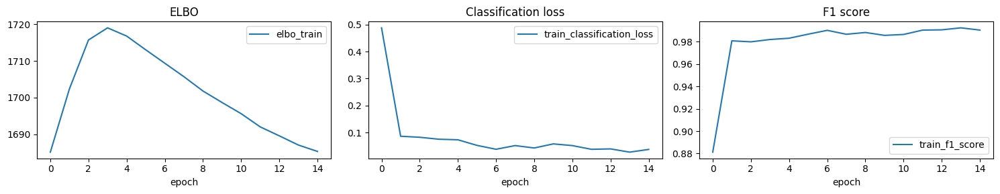

In [17]:
if USE_SCANVI:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3))
    scanvi_ref.history["elbo_train"].plot(ax=axes[0], title="ELBO")
    scanvi_ref.history["train_classification_loss"].plot(ax=axes[1], title="Classification loss")
    scanvi_ref.history["train_f1_score"].plot(ax=axes[2], title="F1 score")
    plt.tight_layout(); plt.show()


In [18]:
ref.obsm["X_scANVI"] = scanvi_ref.get_latent_representation()
sc.pp.neighbors(ref, use_rep="X_scANVI", key_added="scANVI_neighbors")
sc.tl.umap(ref, neighbors_key="scANVI_neighbors", min_dist=0.3)

In [19]:
ref.obs.columns

Index(['reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex',
       'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP',
       'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label',
       'Neighborhood_name', 'Neighborhood_bootstrapping_probability',
       'Neighborhood_aggregate_probability',
       'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name',
       'Class_bootstrapping_probability', 'Class_aggregate_probability',
       'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name',
       'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability',
       'Subclass_correlation_coefficient', 'Group_label', 'Group_name',
       'Group_bootstrapping_probability', 'Group_aggregate_probability',
       'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name',
       'Cluster_alias', 'Cluster_bootstrapping_probability',
       'Cluster_aggregate_probability', 'Cluster_correlation_coefficient',
      

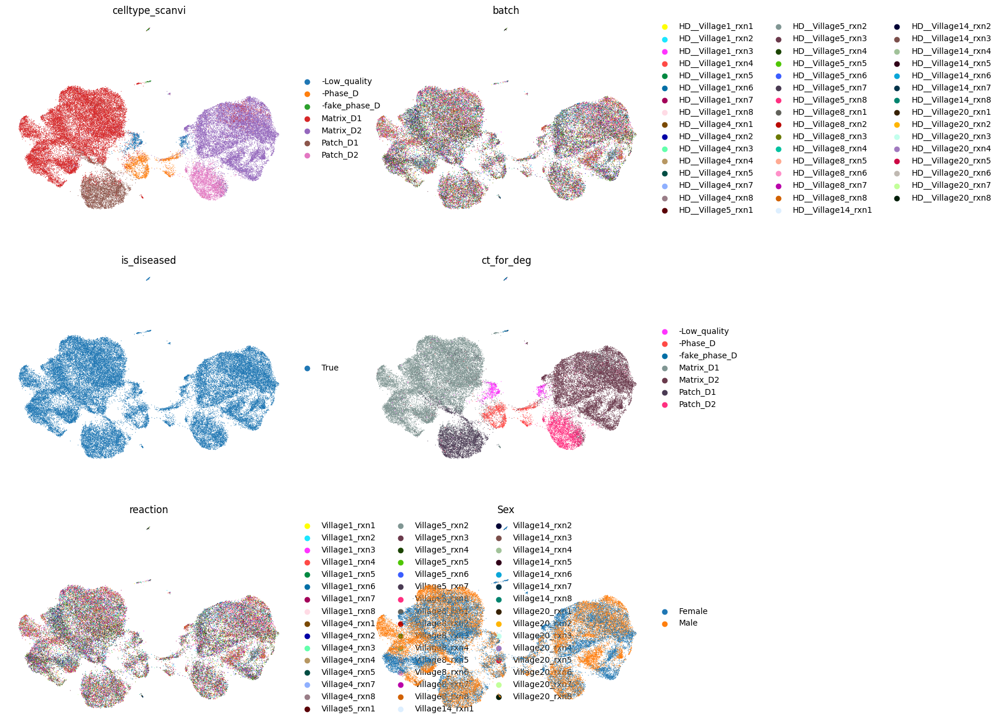

In [20]:
sc.pl.umap(ref, color=[LABELS_KEY, "batch", "is_diseased", "ct_for_deg", "reaction", "Sex"], ncols=2, frameon=False)


In [21]:
pd.crosstab(ref.obs["village"], ref.obs["is_diseased"])
pd.crosstab(ref.obs["village"], ref.obs["Sex"])

Sex,Female,Male
village,,
Village1,4901,9896
Village4,3383,602
Village5,5007,3761
Village8,3165,7422
Village14,3451,269
Village20,2029,1338


Reference self-accuracy: 0.9167

               precision    recall  f1-score   support

 -Low_quality       0.67      0.97      0.79       752
     -Phase_D       0.77      0.98      0.86      1402
-fake_phase_D       0.54      1.00      0.70        73
    Matrix_D1       0.98      0.89      0.94     21230
    Matrix_D2       0.95      0.92      0.94     14249
     Patch_D1       0.78      0.95      0.86      4710
     Patch_D2       0.80      0.94      0.87      2808

     accuracy                           0.92     45224
    macro avg       0.78      0.95      0.85     45224
 weighted avg       0.93      0.92      0.92     45224



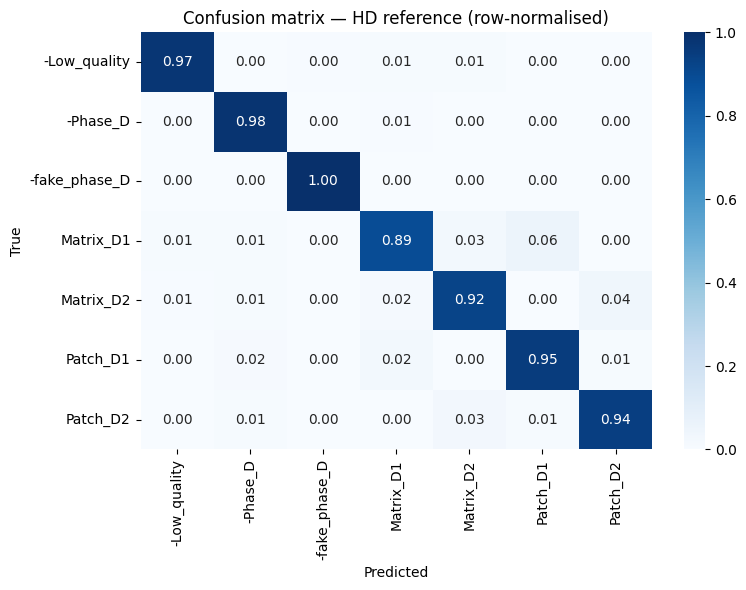

In [22]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

if USE_SCANVI:
    ref_preds = scanvi_ref.predict(ref)
    ref_true  = ref.obs[LABELS_KEY]
    labels    = sorted(ref_true.unique())

    print(f"Reference self-accuracy: {(ref_true == ref_preds).mean():.4f}\n")
    print(classification_report(ref_true, ref_preds, target_names=labels, zero_division=0))

    cm = confusion_matrix(ref_true, ref_preds, labels=labels, normalize="true")
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title("Confusion matrix — HD reference (row-normalised)")
    plt.tight_layout(); plt.show()
else:
    print("USE_SCANVI=False: no classifier to self-validate (plain scVI has no predict()).")


In [23]:
ref_model_dir = f"{BASE_PATH}/models/scanvi_ref/"
os.makedirs(ref_model_dir, exist_ok=True)
scanvi_ref.save(ref_model_dir, overwrite=True)

ref_processed_path = f"{BASE_PATH}/ref_data/reference_adata.h5ad"
os.makedirs(os.path.dirname(ref_processed_path), exist_ok=True)
ref.write(ref_processed_path)
print(f"Reference model saved to {ref_model_dir}")
print(f"Processed reference adata saved to {ref_processed_path}")


/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


Reference model saved to /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI/models/scanvi_ref/
Processed reference adata saved to /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI/ref_data/reference_adata.h5ad


## PART B — Map NucSeq + SlideTags jointly onto the HD reference (scArches surgery)

NucSeq and SlideTags are concatenated into a **single query** before surgery (rather than mapped one at a time), so:
- shared genes/HVGs are aligned once,
- the two modalities are fine-tuned together and can share statistical strength,
- donors present in both (Section 4) are visible to the model together in one training run.

Restart from here if you only change something in Part B (reference model + processed reference adata are reloaded from disk).

In [24]:
ref = sc.read_h5ad(ref_processed_path)
print(f"Loaded processed reference: {ref.shape}")


Loaded processed reference: (45224, 3000)


In [25]:
QUERY_NAMES_PRESENT = [name for name in QUERY_NAMES if name in adatas]
assert QUERY_NAMES_PRESENT, f"None of QUERY_NAMES={QUERY_NAMES} are present in `adatas` -- check RAW_PATHS"

query = anndata.concat(
    {name: adatas[name] for name in QUERY_NAMES_PRESENT},
    join="inner",
    label="dataset",
    index_unique="-",
)
query.obs[LABELS_KEY] = UNLABELLED           # masked during surgery training
query.obs[f"{TRAIN_LABEL_COL}_true"] = query.obs[TRAIN_LABEL_COL].astype(str)  # keep ground truth for validation below

# batch names are already dataset-prefixed (Section 5), so different datasets' batches never collide
batch_counts = query.obs["batch"].value_counts()
query = query[query.obs["batch"].isin(batch_counts[batch_counts >= MIN_BATCH_SIZE].index)].copy()
query.var_names_make_unique()
print(f"Query ({' + '.join(QUERY_NAMES_PRESENT)}): {query.shape}")
print(query.obs["dataset"].value_counts())


Query (nucseq + slidetags): (94038, 30589)
dataset
slidetags    78502
nucseq       15536
Name: count, dtype: int64


In [26]:
ModelClass = scvi.model.SCANVI if USE_SCANVI else scvi.model.SCVI

ModelClass.prepare_query_anndata(query, ref_model_dir)
scanvi_query = ModelClass.load_query_data(query, ref_model_dir)
scanvi_query.train(
    max_epochs=SURGERY_EPOCHS,
    batch_size=BATCH_SIZE,
    plan_kwargs={"weight_decay": 0.0},
    datasplitter_kwargs={"num_workers": 16},
)


INFO     File /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI/models/scanvi_ref/model.pt already downloaded        


INFO     Found 100.0% reference vars in query data.                                                                
INFO     File /home/gdallagl/myworkdir/XDP/data/_old/MSN_scVI/models/scanvi_ref/model.pt already downloaded        
INFO     Training for 20 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 85 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


Training:   0%|          | 0/20 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.


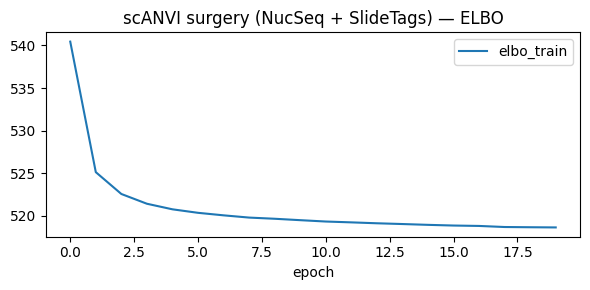

In [27]:
fig, ax = plt.subplots(figsize=(6, 3))
for key in scanvi_query.history:
    if "elbo" in key:
        scanvi_query.history[key].plot(ax=ax, label=key)
ax.set(title="scANVI surgery (NucSeq + SlideTags) — ELBO"); ax.legend()
plt.tight_layout(); plt.show()


In [28]:
if USE_SCANVI:
    query.obs["predicted_scanvi"] = scanvi_query.predict()
    pred_probs = scanvi_query.predict(soft=True)
    query.obs["prediction_confidence"] = pred_probs.max(axis=1).values

    print("Query predictions:")
    print(query.obs["predicted_scanvi"].value_counts())
    print(f"\nMedian confidence: {query.obs['prediction_confidence'].median():.3f}")
else:
    print("USE_SCANVI=False: no predicted labels (unsupervised scVI mode) -- "
          "inspect ct_for_deg_true / cluster the shared latent space yourself instead.")


Query predictions:
predicted_scanvi
Matrix_D2        82866
Matrix_D1         3985
Patch_D1          2691
Patch_D2          2113
-Low_quality      1866
-fake_phase_D      282
-Phase_D           235
Name: count, dtype: int64

Median confidence: 0.999


In [29]:
ref.obs["ct_for_deg"].unique().tolist()

['Matrix_D2',
 'Matrix_D1',
 'Patch_D2',
 'Patch_D1',
 '-Low_quality',
 '-Phase_D',
 '-fake_phase_D']

## Validate against ground truth (this query is unusual: we actually know the true subtype)

Unlike a typical scArches query, NucSeq/SlideTags cells here already have their own `ct_for_deg` subtype label (`ct_for_deg_true`), only masked during training. Comparing `predicted_scanvi` to it gives a direct, quantitative answer to whether the reference (trained on the chosen cell-type subset only) transfers well — this is the empirical version of the "does subsetting hurt learning" question, per dataset.

=== nucseq: accuracy = 0.7808 (15536 cells) ===
               precision    recall  f1-score   support

 -Low_quality       0.95      0.51      0.67      3447
     -Phase_D       0.00      0.00      0.00         0
       -TAFA1       0.00      0.00      0.00       579
-fake_phase_D       0.00      0.00      0.00         0
    Matrix_D1       0.85      0.89      0.87      3824
    Matrix_D2       0.85      0.87      0.86      4276
     Patch_D1       0.70      0.97      0.82      1937
     Patch_D2       0.64      0.97      0.77      1398
eMSN_StrioMat       0.00      0.00      0.00        56
      non-MSN       0.00      0.00      0.00        19

     accuracy                           0.78     15536
    macro avg       0.40      0.42      0.40     15536
 weighted avg       0.80      0.78      0.77     15536



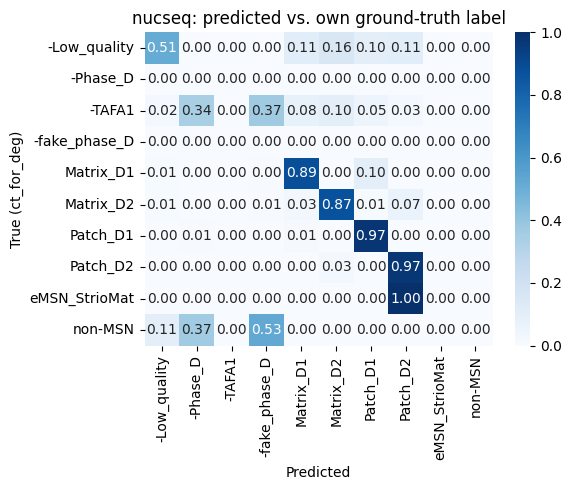

=== slidetags: accuracy = 0.2948 (78502 cells) ===
                          precision    recall  f1-score   support

            -Low_quality       0.00      0.00      0.00     10942
     -Mito_cluster_patch       0.00      0.00      0.00      1207
-Non_neuron_Neun_Pos_Lib       0.00      0.00      0.00      3466
        Cholinergic GABA       0.00      0.00      0.00         2
               Matrix_D1       0.00      0.00      0.00     20974
               Matrix_D2       0.29      1.00      0.46     23140
                Patch_D1       0.00      0.00      0.00      6592
                Patch_D2       0.00      0.00      0.00      4610
                   TAFA1       0.00      0.00      0.00      5183
                 non-MSN       0.00      0.00      0.00      2386

                accuracy                           0.29     78502
               macro avg       0.03      0.10      0.05     78502
            weighted avg       0.09      0.29      0.13     78502



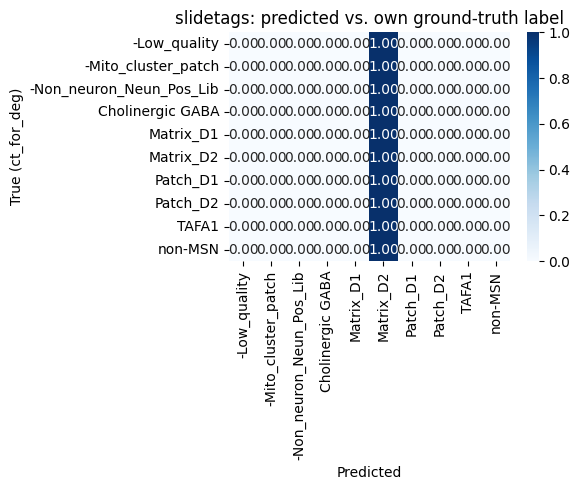

In [30]:
if USE_SCANVI:
    for name in query.obs["dataset"].unique():
        sub = query.obs[query.obs["dataset"] == name]
        labels = sorted(set(sub[f"{TRAIN_LABEL_COL}_true"]) | set(sub["predicted_scanvi"]))
        acc = (sub[f"{TRAIN_LABEL_COL}_true"] == sub["predicted_scanvi"]).mean()
        print(f"=== {name}: accuracy = {acc:.4f} ({len(sub)} cells) ===")
        print(classification_report(sub[f"{TRAIN_LABEL_COL}_true"], sub["predicted_scanvi"], labels=labels, zero_division=0))

        cm = confusion_matrix(sub[f"{TRAIN_LABEL_COL}_true"], sub["predicted_scanvi"], labels=labels, normalize="true")
        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels)
        plt.xlabel("Predicted"); plt.ylabel(f"True ({TRAIN_LABEL_COL})")
        plt.title(f"{name}: predicted vs. own ground-truth label")
        plt.tight_layout(); plt.show()
else:
    print("USE_SCANVI=False: nothing to validate against ground truth (no predicted_scanvi column).")


In [31]:
if USE_SCANVI:

    n_query = query.n_obs
    n_high  = (query.obs["prediction_confidence"] >= CONF_THRESHOLD).sum()
    print(f"High confidence (>= {CONF_THRESHOLD}): {n_high}/{n_query} ({100*n_high/n_query:.1f}%)")

    query.obs["predicted_filtered"] = query.obs["predicted_scanvi"].copy()
    query.obs.loc[query.obs["prediction_confidence"] < CONF_THRESHOLD, "predicted_filtered"] = "Low_confidence"
else:
    print("USE_SCANVI=False: no predicted labels to filter by confidence (unsupervised scVI mode).")

High confidence (>= 0.8): 93357/94038 (99.3%)


## Joint visualization — HD + NucSeq + SlideTags in the shared latent space

In [32]:
print("Getting latent representations for reference and query from the surgery model...")
ref.obsm["X_scANVI"] = scanvi_query.get_latent_representation(ref)
query.obsm["X_scANVI"] = scanvi_query.get_latent_representation()

for obj in [ref, query]:
    for col in obj.obs.select_dtypes("category").columns:
        obj.obs[col] = obj.obs[col].astype(str)

ref.obs["predicted_scanvi"] = ref.obs[LABELS_KEY]
ref.obs[f"{TRAIN_LABEL_COL}_true"] = ref.obs[LABELS_KEY]

adata_full = anndata.concat([ref, query], join="inner")
adata_full.obs_names_make_unique()
adata_full.obsm["X_scANVI"] = np.vstack([ref.obsm["X_scANVI"], query.obsm["X_scANVI"]])

adata_full.obs["label_combined"] = adata_full.obs[f"{TRAIN_LABEL_COL}_true"].copy()

sc.pp.neighbors(adata_full, use_rep="X_scANVI", key_added="scANVI_neighbors")
sc.tl.umap(adata_full, neighbors_key="scANVI_neighbors", min_dist=0.3)
adata_full.obsm["X_umap_scANVI"] = adata_full.obsm["X_umap"].copy()


Getting latent representations for reference and query from the surgery model...
INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             


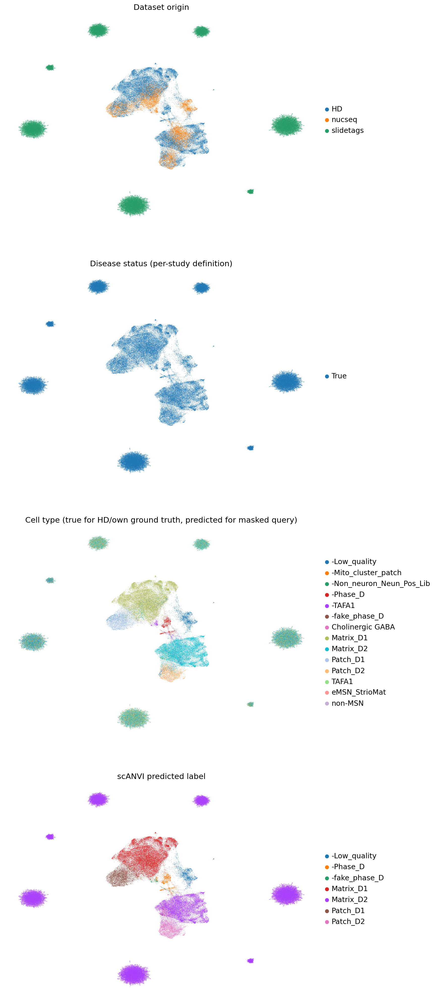

In [33]:
sc.settings.set_figure_params(figsize=(10, 8))
fig, ax = plt.subplots(4,1, figsize=(10, 32))
ax = ax.flatten()
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="dataset", frameon=False, title="Dataset origin", ax=ax[0], show=False)
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="is_diseased", frameon=False, title="Disease status (per-study definition)", ax=ax[1], show=False)
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="label_combined", frameon=False, title="Cell type (true for HD/own ground truth, predicted for masked query)", ax=ax[2], show=False)
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="predicted_scanvi", frameon=False, title="scANVI predicted label", ax=ax[3], show=False)
plt.show()


In [34]:
from utils import label_mapping_utils as lmu


In [35]:
adata_full.obs["ct_for_deg"].value_counts()

ct_for_deg
Matrix_D1                   46028
Matrix_D2                   41665
-Low_quality                15141
Patch_D1                    13239
Patch_D2                     8816
TAFA1                        5183
-Non_neuron_Neun_Pos_Lib     3466
non-MSN                      2405
-Phase_D                     1402
-Mito_cluster_patch          1207
-TAFA1                        579
-fake_phase_D                  73
eMSN_StrioMat                  56
Cholinergic GABA                2
Name: count, dtype: int64

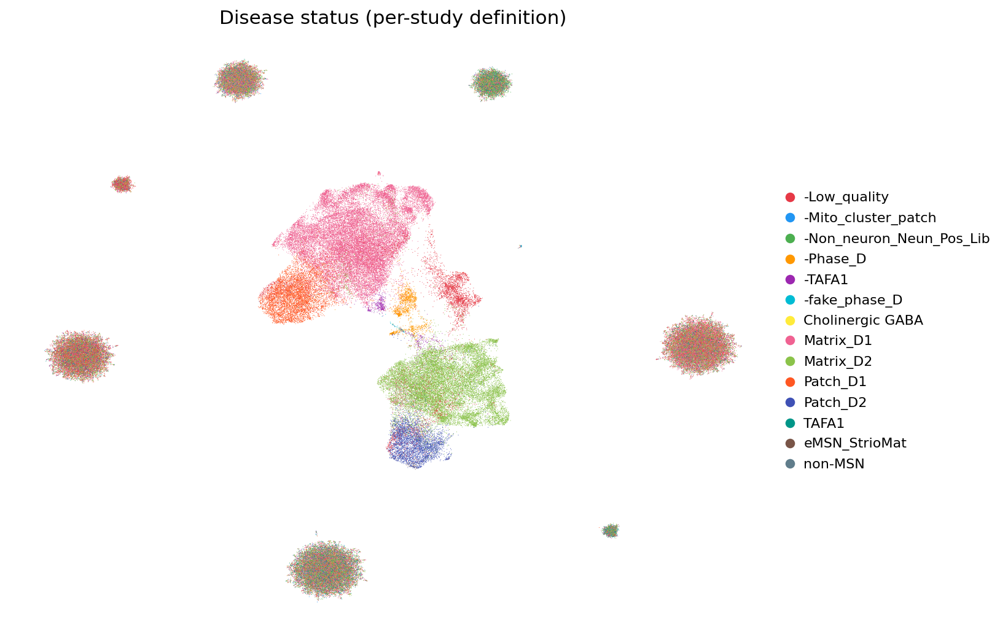

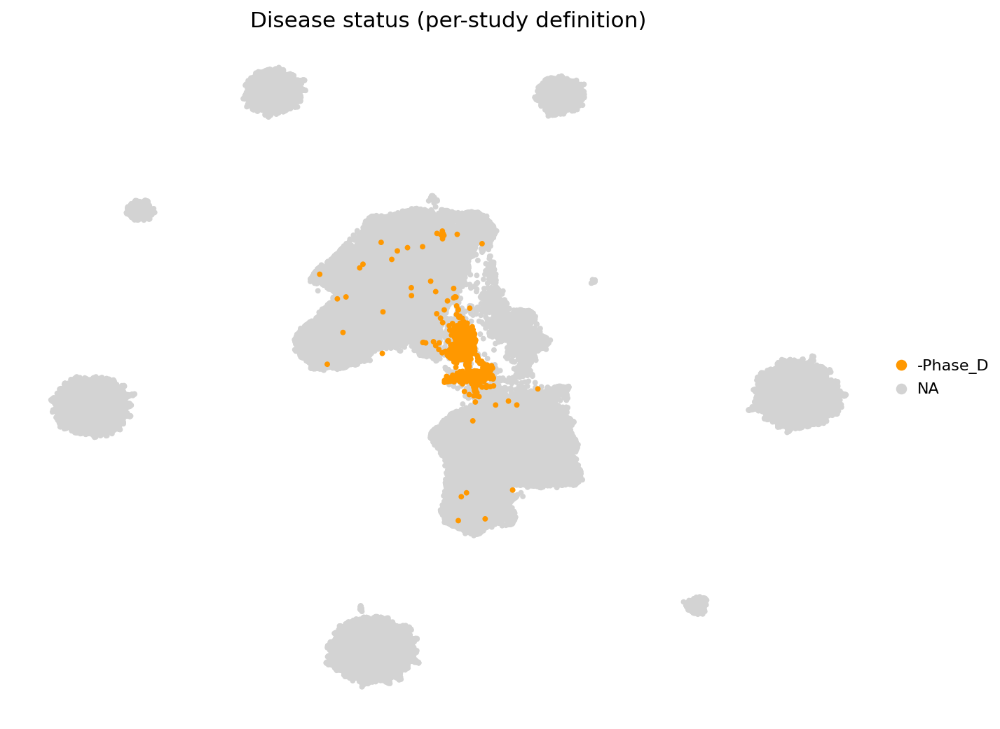

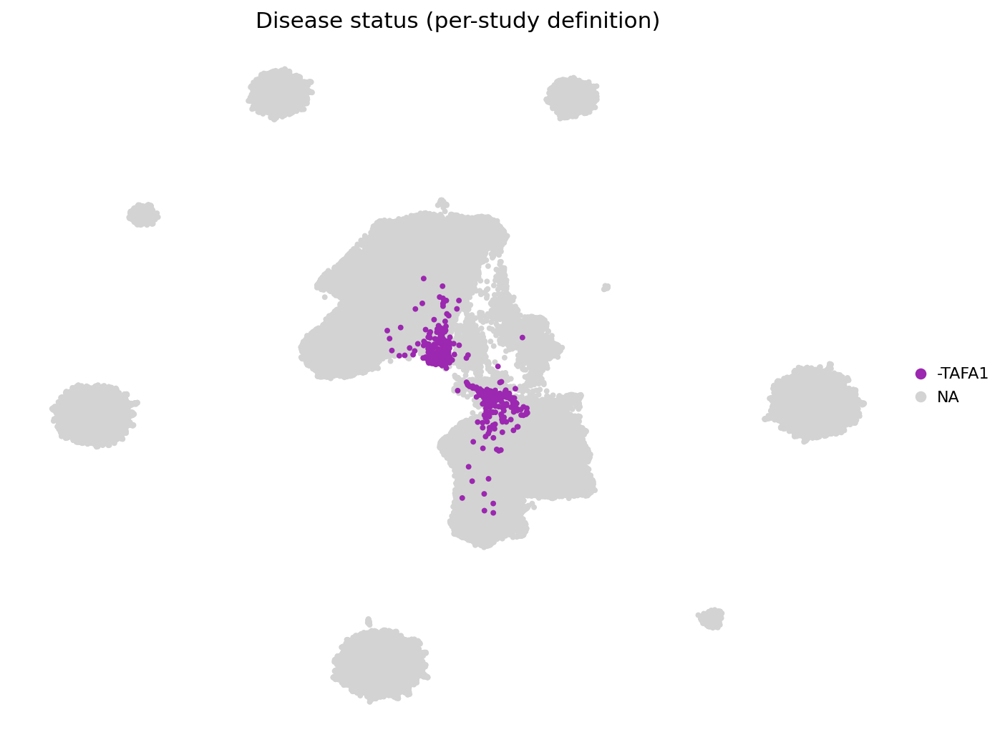

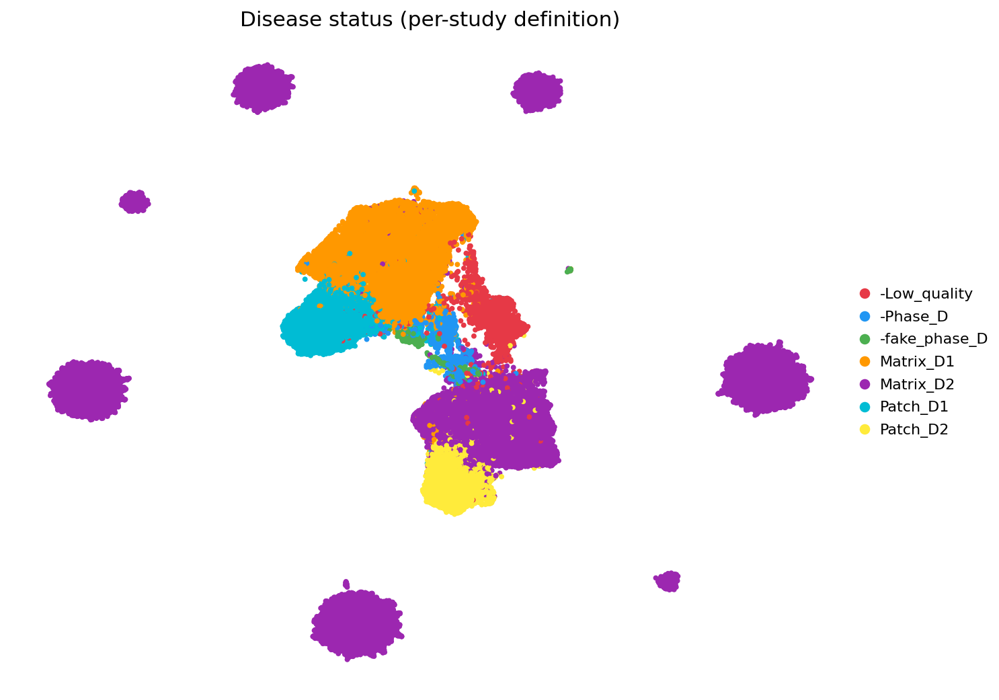

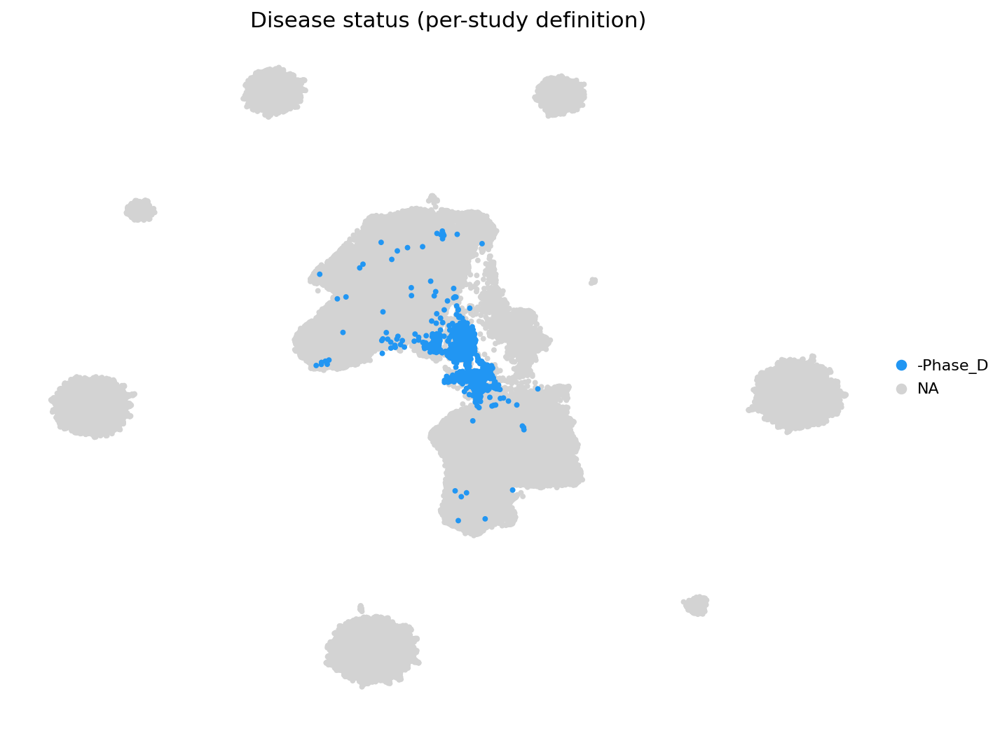

In [36]:
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="ct_for_deg", frameon=False, title="Disease status (per-study definition)", palette=lmu.custom_palette)
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="ct_for_deg", frameon=False, groups=["-Phase_D"], title="Disease status (per-study definition)", palette=lmu.custom_palette, size=50)
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="ct_for_deg", frameon=False, groups=["-TAFA1"], title="Disease status (per-study definition)", palette=lmu.custom_palette, size=50)
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="predicted_scanvi", frameon=False, title="Disease status (per-study definition)", palette=lmu.custom_palette, size=50)
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="predicted_scanvi",groups=["-Phase_D"], frameon=False, title="Disease status (per-study definition)", palette=lmu.custom_palette, size=50)


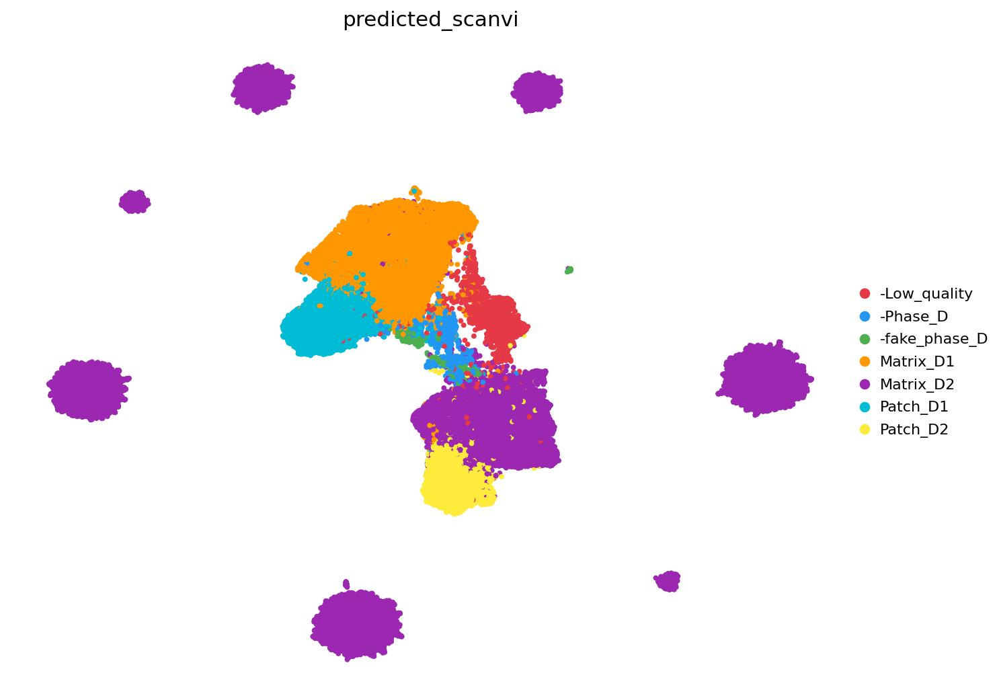

In [37]:
sc.pl.embedding(adata_full, basis="X_umap_scANVI", color="predicted_scanvi", frameon=False, palette=lmu.custom_palette, size=50)


In [38]:
adata_full.var

""
ENSG00000000005
ENSG00000000460
ENSG00000000971
ENSG00000001626
ENSG00000002587
...
ENSG00000283517
ENSG00000283538
ENSG00000283692
ENSG00000284052


In [39]:
slidetags_raw = sc.read_h5ad(RAW_PATHS["slidetags"], backed="r")  # obs/obsm load eagerly even in backed mode; only X stays lazy

spatial_coords = pd.DataFrame(
    slidetags_raw.obsm["spatial"],
    index=slidetags_raw.obs_names,
    columns=["spatial_x", "spatial_y"],
)

# adata_full's slidetags barcodes carry the "-slidetags" suffix appended by
# anndata.concat's index_unique="-" back in Part B
is_slidetags = adata_full.obs["dataset"] == "slidetags"
orig_barcodes = adata_full.obs_names[is_slidetags].str.replace(r"-slidetags$", "", regex=True)

n_matched = orig_barcodes.isin(spatial_coords.index).sum()
print(f"{n_matched}/{len(orig_barcodes)} slidetags barcodes matched back to the raw file")

adata_full.obs["spatial_x"] = np.nan
adata_full.obs["spatial_y"] = np.nan
adata_full.obs.loc[is_slidetags, "spatial_x"] = spatial_coords.loc[orig_barcodes, "spatial_x"].values
adata_full.obs.loc[is_slidetags, "spatial_y"] = spatial_coords.loc[orig_barcodes, "spatial_y"].values


78502/78502 slidetags barcodes matched back to the raw file


SCF-18-003


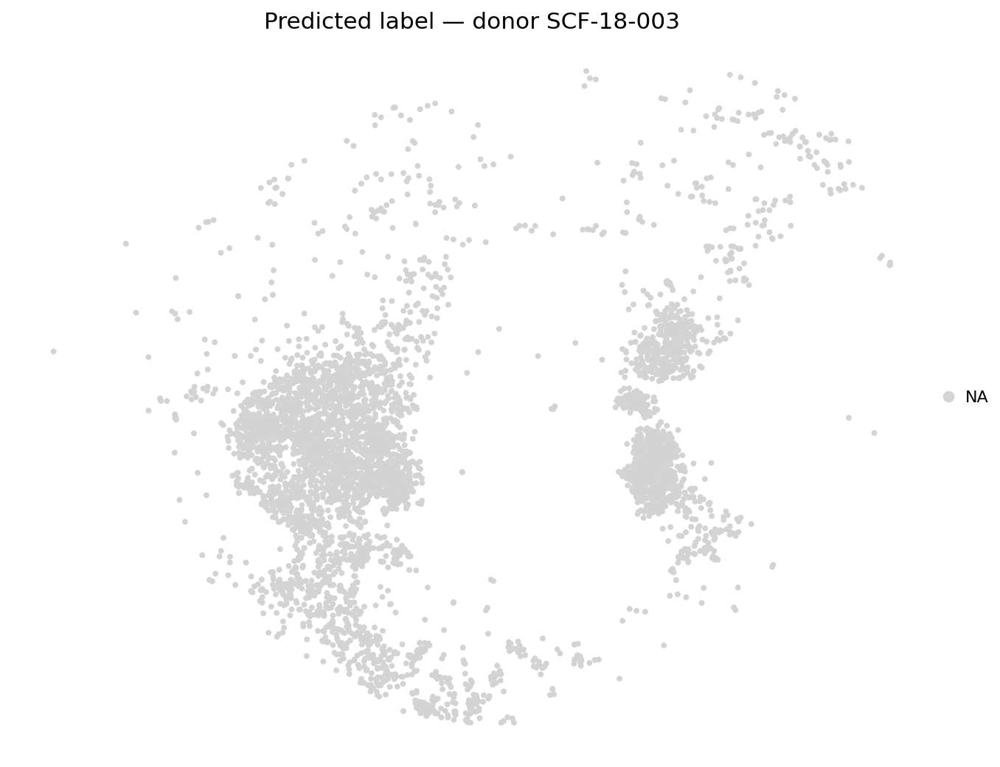

SCF-20-025


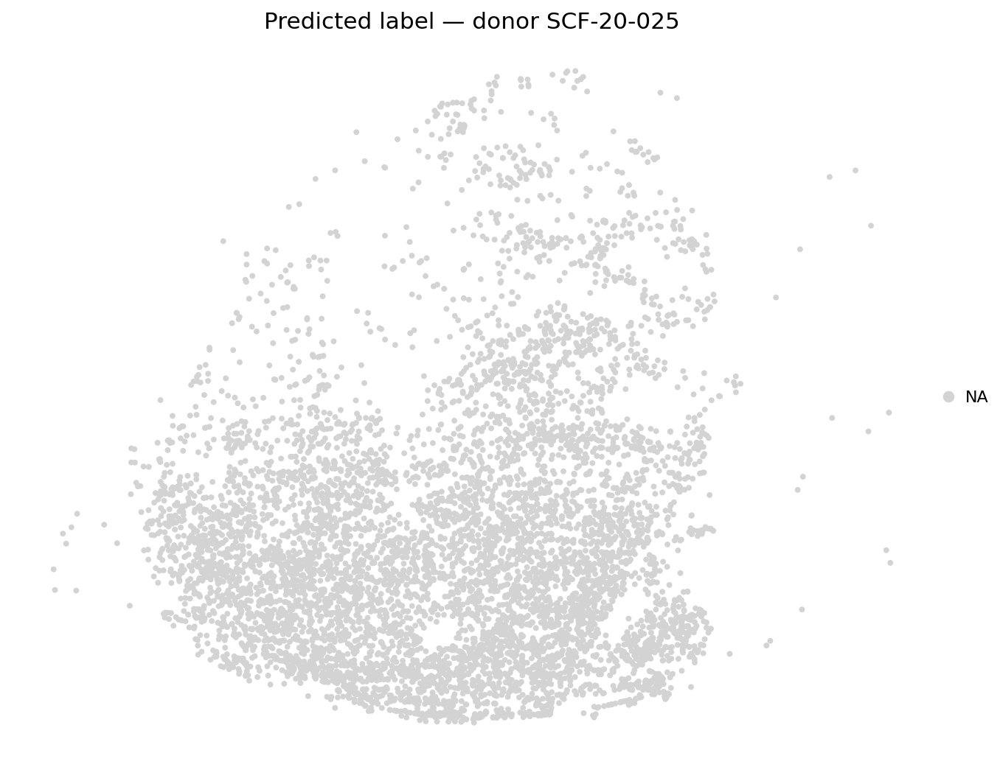

SCF-19-014


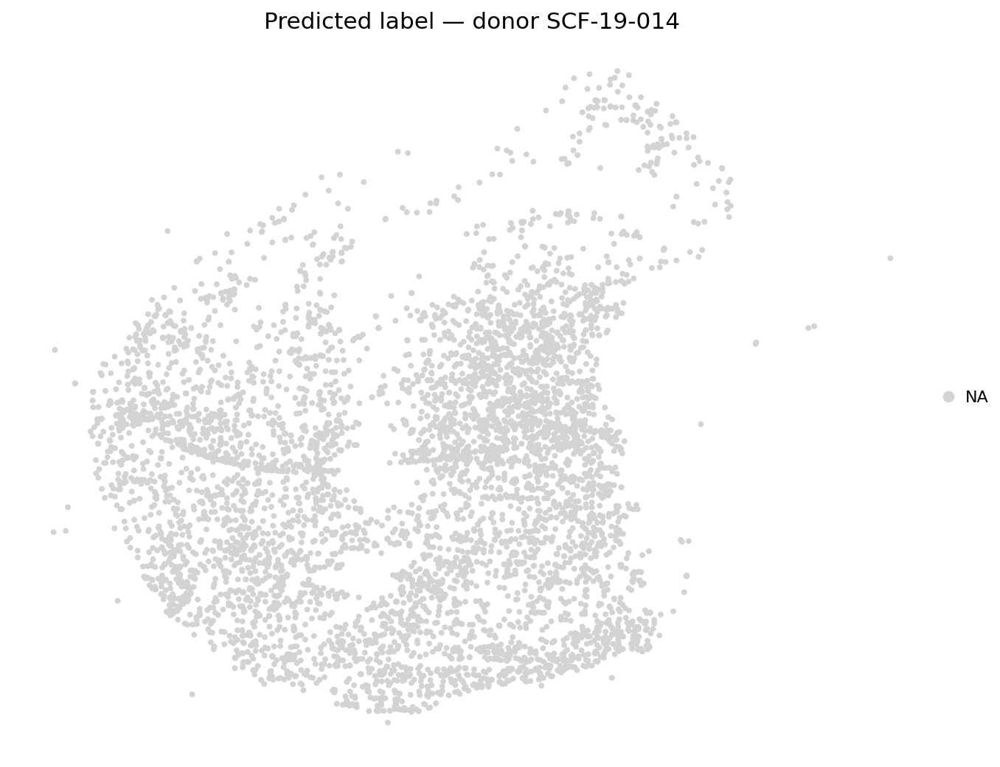

SCF-20-024


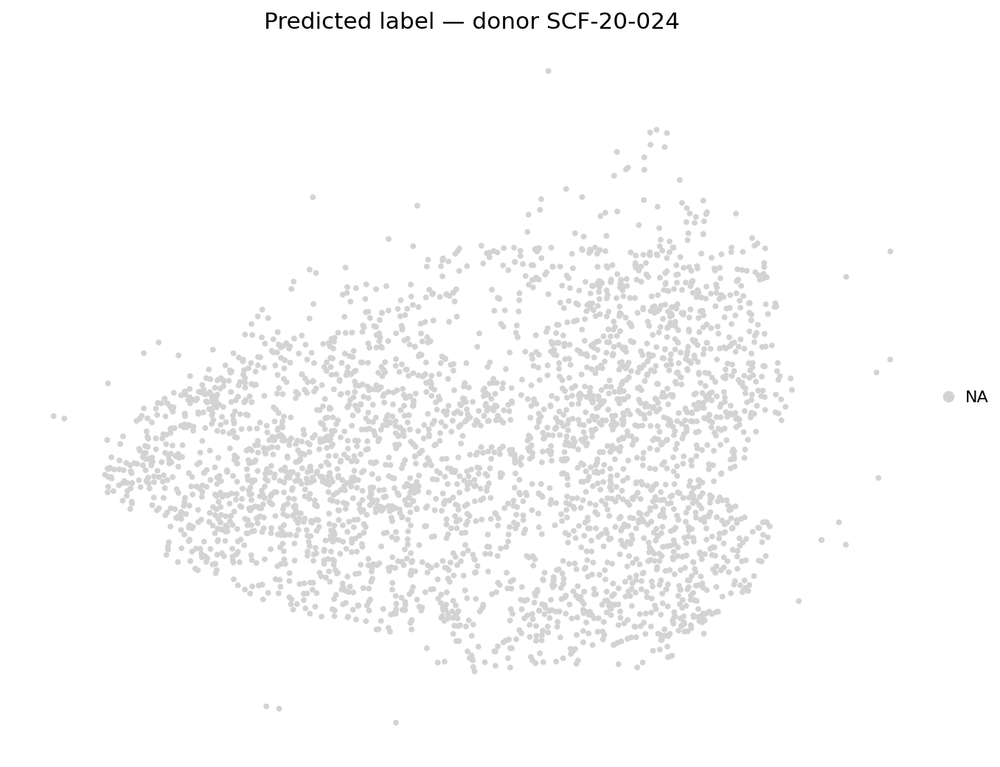

SCF-20-026


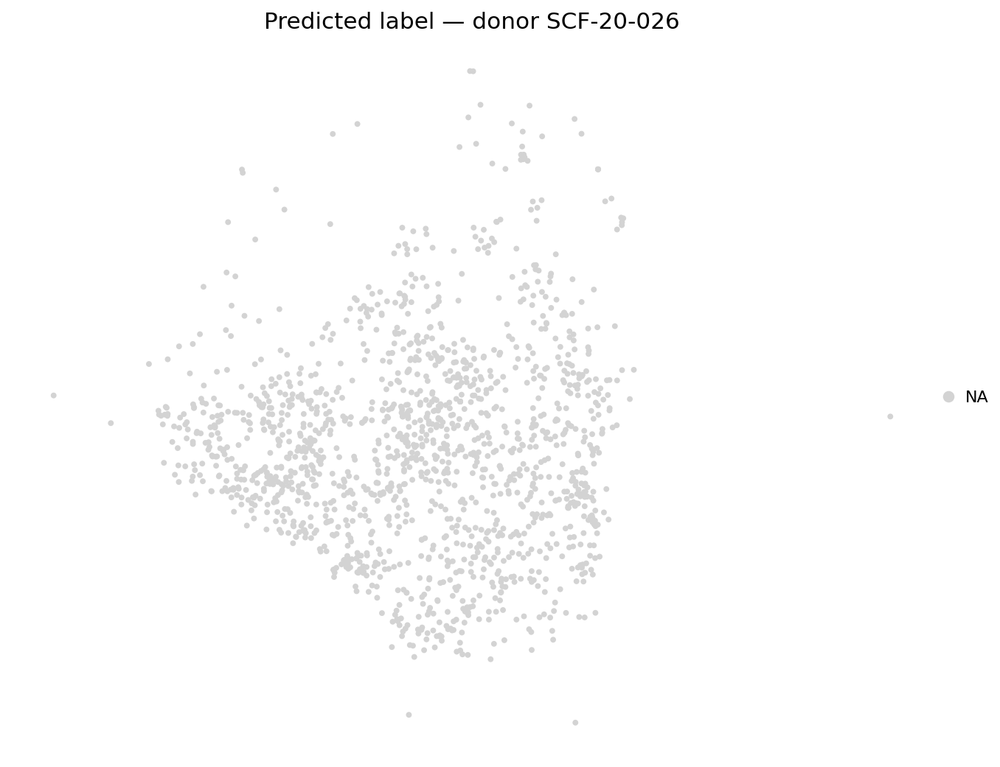

SCF-22-043


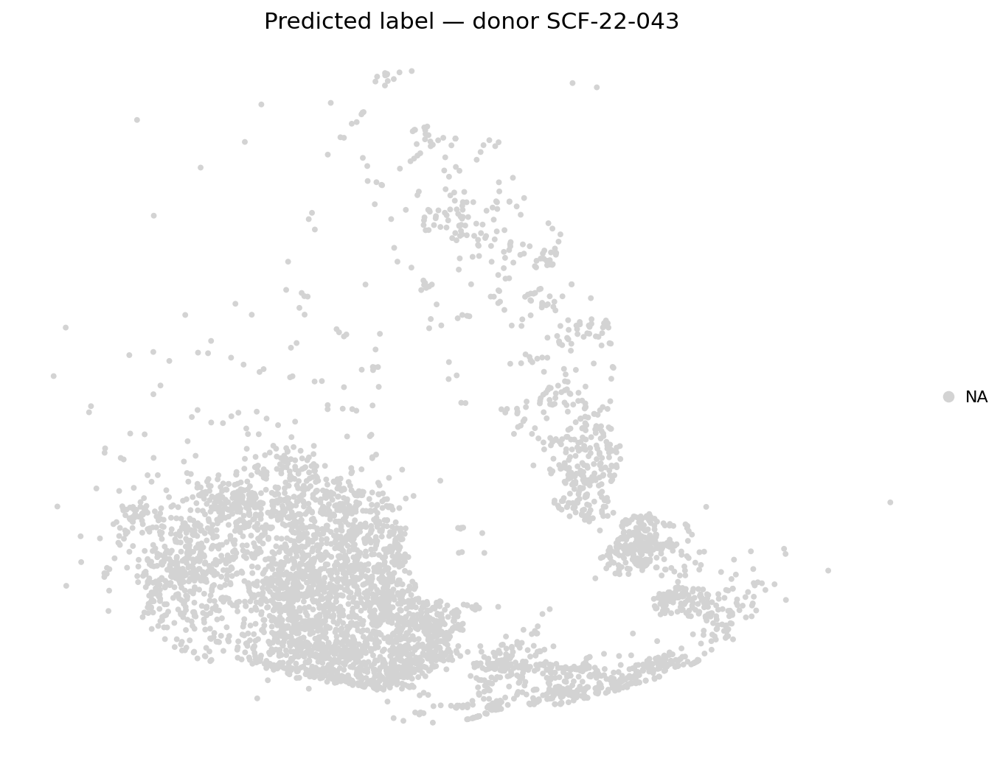

SCF-18-006


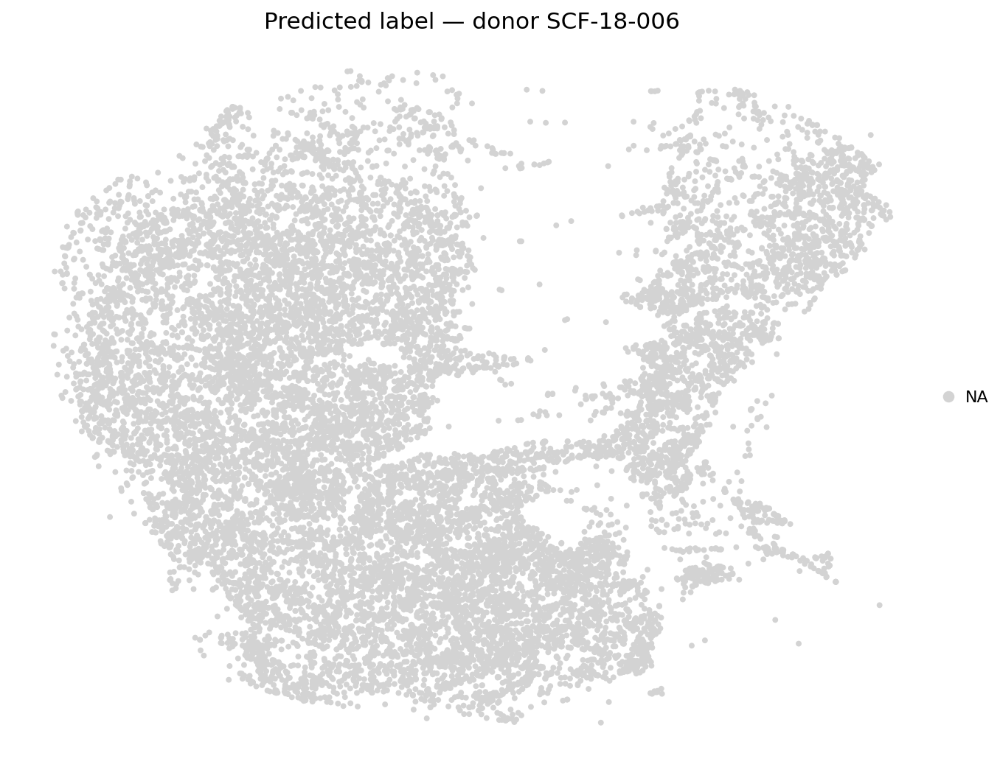

SCF-21-032


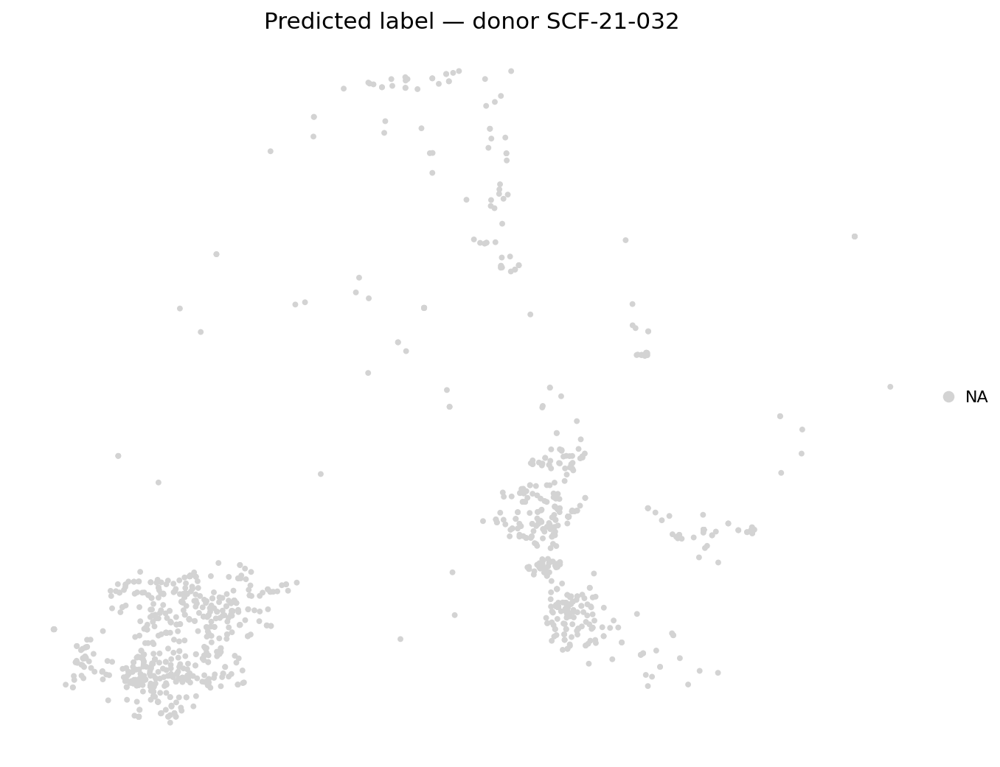

In [40]:
for d in adata_full.obs.loc[adata_full.obs["dataset"] == "slidetags", "donor_id_unified"].unique():
    print(d)
    tmp = adata_full[
        (adata_full.obs["dataset"] == "slidetags") &
        (adata_full.obs["donor_id_unified"] == d)
    ].copy()
    tmp.obsm["spatial"] = tmp.obs[["spatial_x", "spatial_y"]].to_numpy()

    sc.pl.embedding(tmp, basis="spatial", color="predicted_scanvi", frameon=False, title=f"Predicted label — donor {d}", palette=lmu.custom_palette, size=50, groups="-Phase_D")
    plt.show()
    #break

In [41]:
# Sanity check for the donor harmonization in Section 4: pick a couple of donors
# profiled in BOTH NucSeq and SlideTags and confirm their cells land in the same region
example_shared_donors = sorted(shared_nucseq_slidetags)[:3]
adata_full.obs["highlight_shared_donor"] = np.where(
    adata_full.obs["donor_id_unified"].isin(example_shared_donors),
    adata_full.obs["donor_id_unified"] + " (" + adata_full.obs["dataset"] + ")",
    "other",
)
sc.pl.embedding(
    adata_full, basis="X_umap_scANVI", color="highlight_shared_donor",
    groups=[d for d in adata_full.obs["highlight_shared_donor"].unique() if d != "other"],
    frameon=False, title="Same donor, two modalities",
)


TypeError: unsupported operand type(s) for +: 'Categorical' and 'str'

## Save outputs

In [ ]:
out_dir = f"{BASE_PATH}/{'_'.join(QUERY_NAMES)}"
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{BASE_PATH}/models/", exist_ok=True)

#query.write(f"{out_dir}/query_mapped.h5ad")
#adata_full.write(f"{out_dir}/combined_HD_nucseq_slidetags_mapped.h5ad")
#scanvi_query.save(f"{BASE_PATH}/models/scanvi_query/", overwrite=True)

save_csv_path = f"{out_dir}/query_mapped_metadata.csv"
#query.obs[[f"{TRAIN_LABEL_COL}_true", "predicted_scanvi", "prediction_confidence", "predicted_filtered", "donor_id_unified", "dataset"]].to_csv(save_csv_path)
print("All saved to", out_dir)


## Alternative integration: Harmony (comparison against the scVI/scArches result above)

`lmu.preprocess_common_pipeline` (in `utils/label_mapping_utils.py`, not modified here) already
supports Harmony via `integrate_with_harmony=True`, but it reuses the **same** `batch_key` argument
for two different things:
1. `sc.pp.highly_variable_genes(..., batch_key=...)` -- scanpy **requires this to be a single column
   name**, not a list.
2. `harmonypy.run_harmony(..., vars_use=batch_key, ...)` -- harmonypy's `vars_use` **does accept a
   list of column names**, and will correct for each of them jointly.

So yes, you can pass multiple covariates to Harmony (e.g. `["batch", "sex"]`), but not through
`lmu.preprocess_common_pipeline` as-is if you want a *different* set of covariates for the HVG step
vs. the Harmony step -- hence the small wrapper below instead of editing the shared util file.

**Recommendation:** start with `harmony_vars_use=["batch"]` (the same technical pooling/library
unit already used as the scVI batch key), not `["batch", "sex"]`. Harmony works by directly
re-centering each covariate level's cluster means -- it has no equivalent of scVI's
precision-weighted shrinkage that lets real biology "push back" against the correction. Since sex is
heavily confounded with cohort here (SlideTags/NucSeq are ~all male, HD is balanced -- XDP is
X-linked), adding `"sex"` to `vars_use` risks Harmony conflating cohort-driven variation with
sex-driven variation and over-correcting real between-study biology. Only add it if you specifically
see sex-driven separation persisting after the `["batch"]`-only run and want it removed too.

Seed set to 42


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
2026-09-04 17:33:11,321 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-09-04 17:33:11 | [INFO] Running Harmony (PyTorch on cuda)
2026-09-04 17:33:11,323 - harmonypy - INFO -   Parameters:
2026-09-04 17:33:11 | [INFO]   Parameters:
2026-09-04 17:33:11,324 - harmonypy - INFO -     max_iter_harmony: 30
2026-09-04 17:33:11 | [INFO]     max_iter_harmony: 30
2026-09-04 17:33:11,325 - harmonypy - INFO -     max_iter_kmeans: 20
2026-09-04 17:33:11 | [INFO]     max_iter_kmeans: 20
2026-09-04 17:33:11,326 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-09-04 17:33:11 | [INFO]     epsilon_cluster: 1e-05
2026-09-04 17:33:11,327 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-09-04 17:33:11 | [INFO]     epsilon_harmony: 0.0001
2026-09-04 17:33:11,328 - harmonypy - INFO -     nclust: 100
2026-0

Computing Leiden clusters...


... storing 'Group_name' as categorical
... storing 'ct_for_deg' as categorical
... storing 'donor_id_unified' as categorical
... storing 'batch' as categorical
... storing 'sex' as categorical


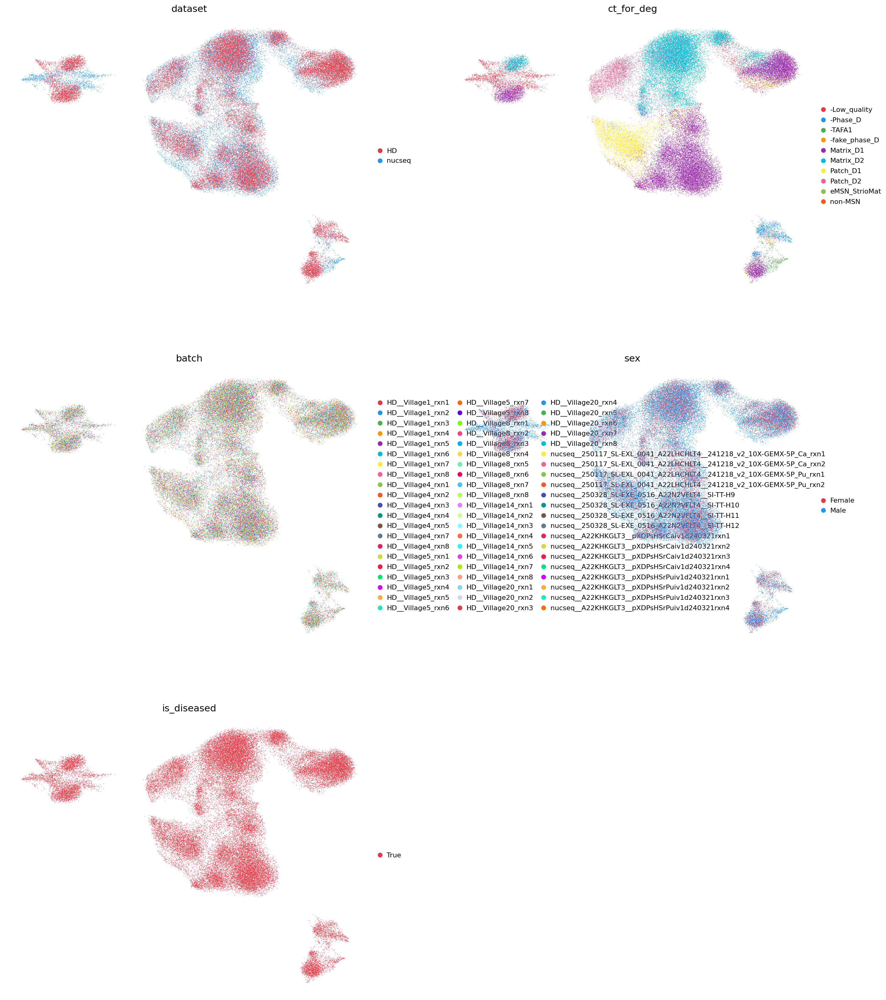

In [ ]:
def run_harmony_integration(adata, hvg_batch_key, harmony_vars_use, n_top_genes=N_TOP_GENES,
                             n_pcs=50, max_iter_harmony=30, resolutions=[0.1, 0.5, 0.3], seed=42):
    """Same steps as lmu.preprocess_common_pipeline(..., integrate_with_harmony=True), but with
    the HVG batch_key (must be a single column) decoupled from Harmony's vars_use (may be a list
    of columns) -- see markdown above for why lmu's version can't do this as-is.
    """
    lmu.set_global_seeds(seed)

    adata.X = adata.layers["counts"].copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.layers["log1p_norm"] = adata.X.copy()

    try:
        sc.pp.highly_variable_genes(adata, n_top_genes=n_top_genes, flavor="seurat_v3",
                                     layer="counts", batch_key=hvg_batch_key)
    except ValueError as e:
        print(f"WARNING: HVG with batch_key='{hvg_batch_key}' failed ({e}), retrying without batch_key")
        sc.pp.highly_variable_genes(adata, n_top_genes=n_top_genes, flavor="seurat_v3",
                                     layer="counts", batch_key=None)


    adata_hvg = adata[:, adata.var["highly_variable"]].copy()
    sc.pp.scale(adata_hvg, max_value=10)
    sc.tl.pca(adata_hvg, svd_solver="randomized", n_comps=n_pcs, random_state=seed)
    adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
    adata.uns["pca"] = adata_hvg.uns["pca"]
    del adata_hvg

    import harmonypy
    ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, vars_use=harmony_vars_use, max_iter_harmony=max_iter_harmony)
    Z = ho.Z_corr
    adata.obsm["X_pca_harmony"] = Z.T if Z.shape[0] != adata.n_obs else Z

    sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_pcs=n_pcs, random_state=seed)
    sc.tl.umap(adata, random_state=seed)

    print("Computing Leiden clusters...")
    for r in resolutions:
        sc.tl.leiden(adata, resolution=r, key_added=f"leiden_{r}_harmony",
                     flavor="igraph", n_iterations=2, random_state=seed)

    adata.X = adata.layers["counts"].copy()  # restore raw counts in X, same convention as the rest of the notebook
    return adata


# all currently-loaded datasets (respects RAW_PATHS/FILTER_STATUS/FILTER_SEX/SUBSET_RUN from Section 1-5),
# not just the query -- Harmony integrates everything jointly rather than reference+surgery
adata_harmony = anndata.concat(
    {name: a for name, a in adatas.items()},
    join="inner",
    label="dataset",
    index_unique="-",
)

gene_symbol_map = pd.concat([a.var["gene_symbol"] for a in adatas.values()])
gene_symbol_map = gene_symbol_map[~gene_symbol_map.index.duplicated(keep="first")]  # same "first wins" rule as before
adata_harmony.var["gene_symbol"] = gene_symbol_map.reindex(adata_harmony.var_names)


adata_harmony = run_harmony_integration(
    adata_harmony,
    hvg_batch_key="donor_id_unified", #batch
    harmony_vars_use=["donor_id_unified", "dataset"],
)



sc.pl.umap(adata_harmony, color=["dataset", TRAIN_LABEL_COL, "batch", "sex", "is_diseased"],
           ncols=2, frameon=False, palette=lmu.custom_palette)


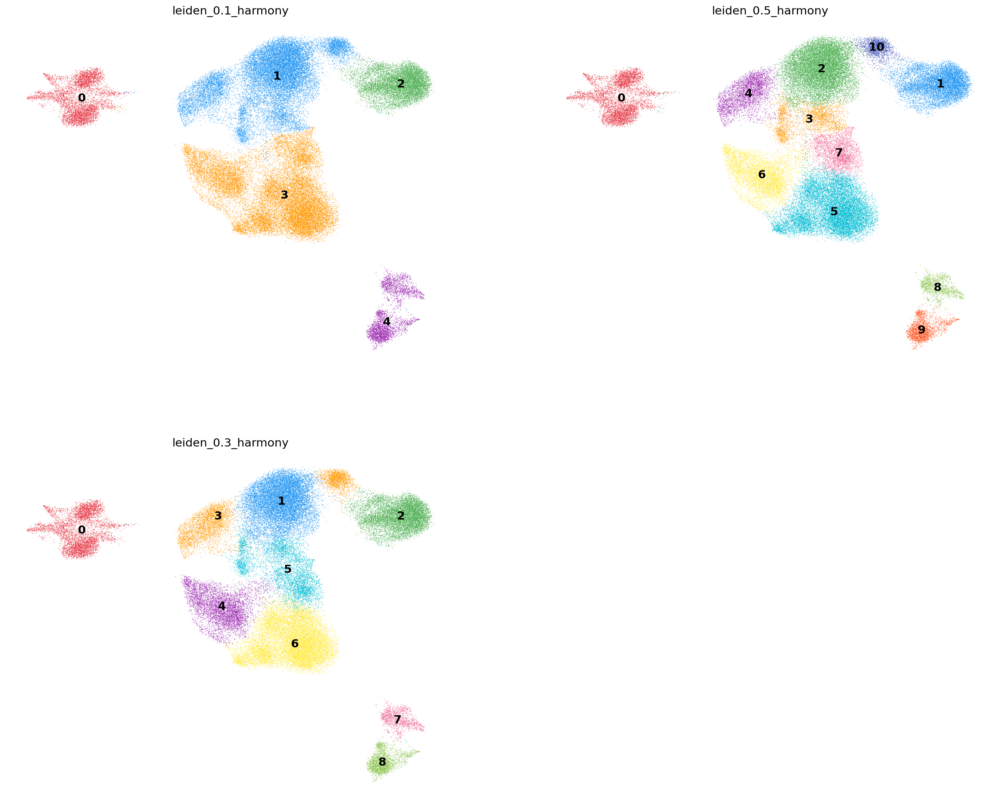

In [ ]:
adata_harmony
sc.pl.umap(adata_harmony, color=[ 'leiden_0.1_harmony', 'leiden_0.5_harmony', 'leiden_0.3_harmony'],
           ncols=2, frameon=False, palette=lmu.custom_palette, legend_loc="on data")


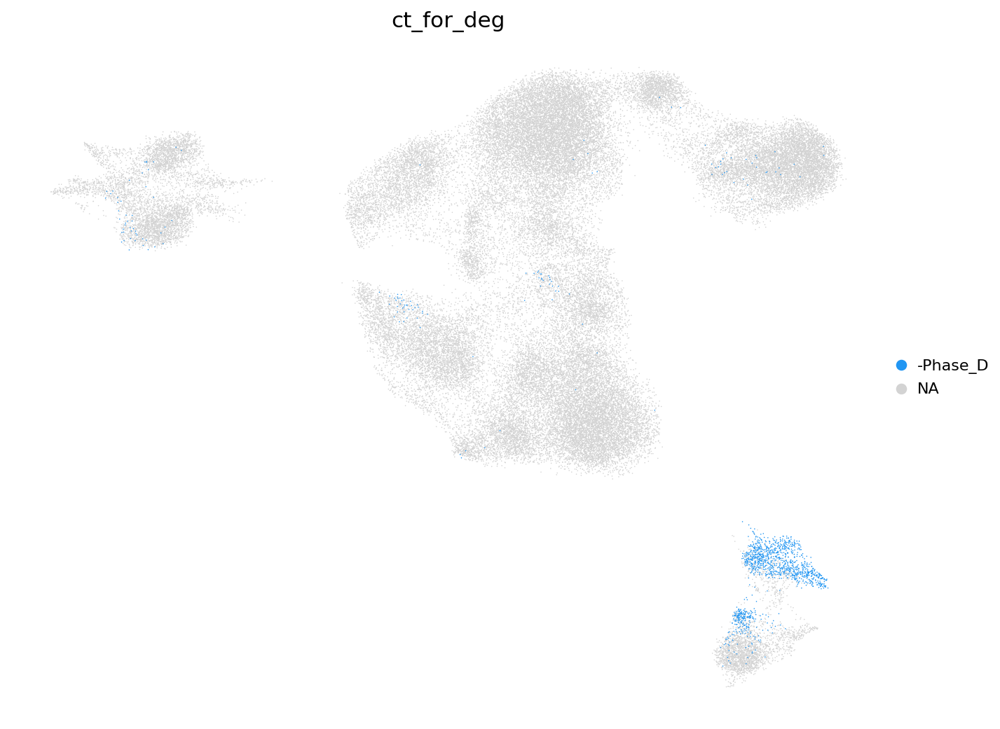

In [ ]:
sc.pl.umap(adata_harmony, color=["ct_for_deg"],
           ncols=2, frameon=False, palette=lmu.custom_palette, groups="-Phase_D")

In [ ]:
adata_harmony.var

,gene_symbol,highly_variable,highly_variable_rank,means,variances,variances_norm
ENSG00000000003,TSPAN6,False,NaN,0.006638,0.007923,0.990298
ENSG00000000005,TNMD,False,NaN,0.000190,0.000190,0.983843
ENSG00000000419,DPM1,False,NaN,1.771645,6.050087,0.809341
ENSG00000000457,SCYL3,False,NaN,0.634803,1.548808,1.009324
ENSG00000000460,C1orf112,True,978.0,1.664865,16.225876,2.406465
...,...,...,...,...,...,...
ENSG00000284484,AC025287.4,False,NaN,0.041062,0.048864,0.805793
ENSG00000284500,AC134980.1,False,NaN,0.001043,0.001422,1.262540
ENSG00000284513,AC006063.2,False,NaN,0.141679,0.176815,0.735231
ENSG00000284543,LINC01226,False,NaN,0.025984,0.037261,1.020903


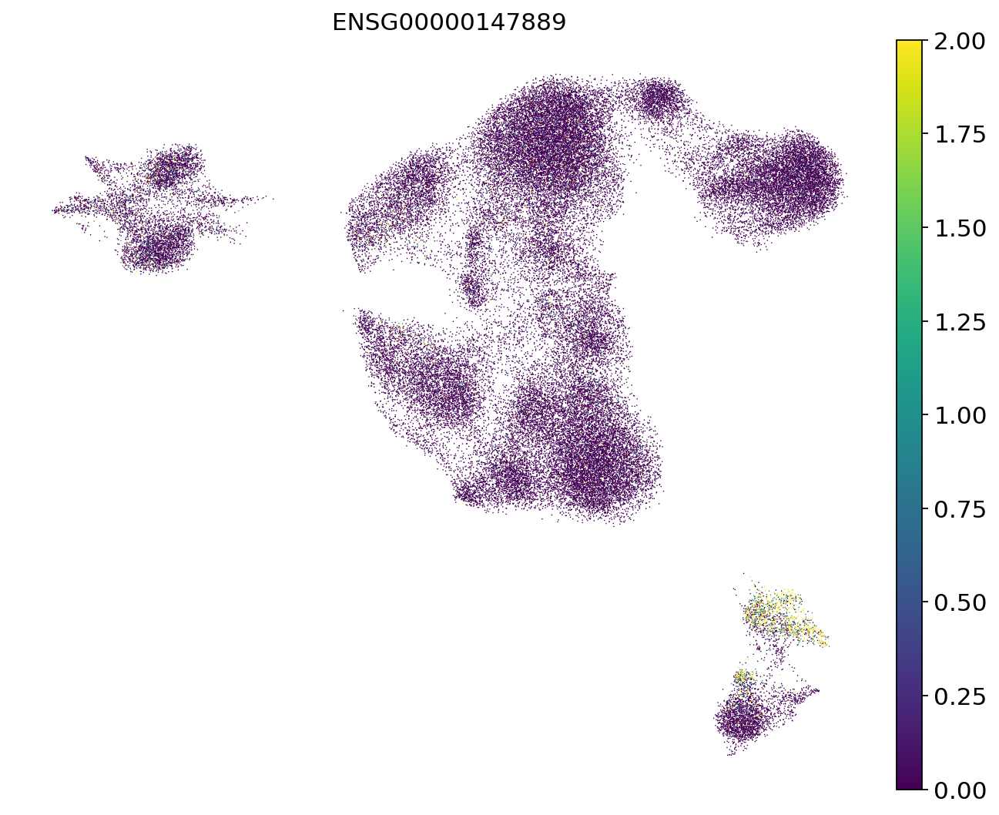

In [ ]:
sc.pl.umap(adata_harmony, color=[ "ENSG00000147889"],
           ncols=2, frameon=False,vmax=2)


In [ ]:
# Wilcoxon
from utils import preprocessing

res = preprocessing.rank_markers_per_cluster(adata_harmony, "leiden_0.5_harmony", layer="log1p_norm", n_genes=50, markers=None,
                                             groups=["10", "8", "9"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata_harmony.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

Cluster 10:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000185565,21.736387,0.908775,9.293266e-105,2.852289e-100,LSAMP
1,ENSG00000153707,20.285423,0.920509,1.729701e-91,1.327200e-87,PTPRD
2,ENSG00000187391,19.068323,0.694702,4.629113e-81,2.367945e-77,MAGI2
3,ENSG00000204442,19.007637,1.793395,1.474458e-80,6.464865e-77,FAM155A
4,ENSG00000021645,17.886333,0.510962,1.507036e-71,4.625394e-68,NRXN3
5,ENSG00000239268,17.858440,0.904678,2.484858e-71,6.933205e-68,AC092691.1
6,ENSG00000145526,17.591969,1.264051,2.838446e-69,6.701354e-66,CDH18
7,ENSG00000083067,17.535864,2.679181,7.628215e-69,1.672323e-65,TRPM3
8,ENSG00000048052,17.452555,1.784214,3.291738e-68,6.314376e-65,HDAC9
9,ENSG00000145242,17.050190,1.833924,3.484035e-65,5.346599e-62,EPHA5


Cluster 8:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000100095,17.616890,2.142799,1.827807e-69,9.349842e-66,SEZ6L
1,ENSG00000196220,16.689220,1.108672,1.570070e-62,6.023575e-59,SRGAP3
2,ENSG00000135905,16.216133,1.625395,3.878584e-59,1.322683e-55,DOCK10
3,ENSG00000185842,15.634670,2.309249,4.226559e-55,1.081013e-51,DNAH14
4,ENSG00000146151,15.500459,0.902634,3.444243e-54,7.550765e-51,HMGCLL1
5,ENSG00000174482,15.443840,1.401502,8.300763e-54,1.698447e-50,LINGO2
6,ENSG00000197121,15.273892,0.864338,1.141507e-52,1.751757e-49,PGAP1
7,ENSG00000248309,15.209612,1.500405,3.053501e-52,4.074697e-49,MEF2C-AS1
8,ENSG00000107186,14.836540,1.034565,8.502909e-50,1.087380e-46,MPDZ
9,ENSG00000144893,14.733193,0.809252,3.946069e-49,4.658183e-46,MED12L


Cluster 9:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000204442,33.278667,2.532092,7.859508e-243,2.412240e-238,FAM155A
1,ENSG00000198947,27.004129,1.963498,1.321770e-160,2.386340e-157,DMD
2,ENSG00000157542,25.966473,4.469977,1.184918e-148,1.818375e-145,KCNJ6
3,ENSG00000107518,25.207695,0.928422,3.298538e-140,4.218280e-137,ATRNL1
4,ENSG00000183662,25.044291,5.212622,2.014671e-138,2.378242e-135,FAM19A1
5,ENSG00000153707,24.628141,0.904368,6.311649e-134,6.679901e-131,PTPRD
6,ENSG00000179915,24.419157,1.007401,1.070585e-131,1.026825e-128,NRXN1
7,ENSG00000140015,24.181070,3.631476,3.519575e-129,3.086366e-126,KCNH5
8,ENSG00000135905,24.003744,2.099029,2.541438e-127,2.108157e-124,DOCK10
9,ENSG00000139117,23.919748,2.905529,1.908465e-126,1.501913e-123,CPNE8
